<a href="https://colab.research.google.com/github/sadiabushra/Forest_Wildfire_Detection/blob/main/Forest_Wildfire_Detection_CNN_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Forest and Wildfire Detection Using Binary CNN Classification

---

## Project Overview

This notebook implements a complete deep learning pipeline for **binary image classification** of forest fires.

### Requirements Covered:
| Requirement | Implementation |
|---|---|
| ✅ 2 DL Models | Custom CNN + MobileNetV2 Transfer Learning |
| ✅ Pre-processing Methods | Rescaling, Outlier Detection, Class Balancing (Sampling) |
| ✅ 2+ Data Augmentation Techniques | RandomFlip + RandomRotation + RandomBrightness + RandomZoom |
| ✅ Hyperparameter Tuning | Keras Tuner (GridSearch/RandomSearch) with Validation Set |
| ✅ 2+ Activation Functions | ReLU (hidden layers) + Sigmoid (output) + ELU (variant) |
| ✅ 2+ Optimization Methods | Adam + SGD with Momentum comparison |
| ✅ Performance Metrics | Accuracy, Precision, Recall, F1-Score, AUC-ROC, Confusion Matrix |

### Dataset
- **Primary:** [Wildfire Detection Image Data — Kaggle](https://www.kaggle.com/datasets/mohnishsaiprasad/forest-fire-images)
- **Classes:** `fire` / `nofire`

---
##  Section 1: Install Dependencies & Load Dataset from Kaggle

###  Setup Instructions:
1. Go to [https://www.kaggle.com](https://www.kaggle.com) → Your Profile → **Settings** → **API** → **Create New Token**
2. Open the downloaded `kaggle.json` — copy your `username` and `key`
3. Paste them into the first cell below, then run all cells

In [ ]:
import os
import json

# ── Paste your Kaggle credentials here ────────────────────────────────────
kaggle_info = {
    "username": "",   # <-- your Kaggle username
    "key": ""          # <-- your Kaggle API key
}

os.makedirs('/root/.kaggle', exist_ok=True)

with open('/root/.kaggle/kaggle.json', 'w') as f:
    json.dump(kaggle_info, f)

os.chmod('/root/.kaggle/kaggle.json', 0o600)
print("✅ Kaggle credentials configured.")

✅ Kaggle credentials configured.


In [ ]:
# ── Install Kaggle and other required packages ─────────────────────────────
!pip install kaggle keras-tuner seaborn scikit-learn --quiet

import os
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import cv2
from pathlib import Path
from collections import Counter

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks, regularizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2, ResNet50V2, EfficientNetB3
import keras_tuner as kt

from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, precision_recall_curve,
    f1_score, precision_score, recall_score, accuracy_score
)
from sklearn.utils.class_weight import compute_class_weight
import gc

def free_model_memory(*args, verbose=True):
    """
    Pass any number of model/base_model variables to delete.
    Example: free_model_memory(mobilenet_model, mobilenet_base)
    """
    for obj in args:
        try:
            del obj
        except:
            pass
    gc.collect()
    tf.keras.backend.clear_session()
    if verbose:
        print("✅ Memory freed — session cleared.")

# ── Reproducibility seeds ──────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ── Constants ──────────────────────────────────────────────────────────────
IMG_SIZE    = (128, 128)
BATCH_SIZE  = 32
EPOCHS_BASE = 30
EPOCHS_TL   = 20

print("✅ All libraries loaded.")
print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {len(tf.config.list_physical_devices('GPU')) > 0}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 11.9 MB/s eta 0:00:00
✅ All libraries loaded.
TensorFlow version: 2.19.0
GPU available: True


In [ ]:
# ── Download dataset directly from Kaggle ─────────────────────────────────
# Source: https://www.kaggle.com/datasets/mohnishsaiprasad/forest-fire-images

!kaggle datasets download -d mohnishsaiprasad/forest-fire-images \
    -p /content/wildfire --unzip --quiet

print("✅ Dataset downloaded!")

# ── Verify folder structure ────────────────────────────────────────────────
DATASET_ROOT = '/content/wildfire'

print("\n📁 Dataset folder structure:")
for root, dirs, files in os.walk(DATASET_ROOT):
    level = root.replace(DATASET_ROOT, '').count(os.sep)
    if level > 2:
        continue
    indent = '  ' * level
    print(f'{indent}📂 {os.path.basename(root)}/')
    if level == 2:
        exts = ('.jpg', '.jpeg', '.png', '.bmp')
        count = sum(1 for f in files if f.lower().endswith(exts))
        print(f'{indent}   └── {count} images')

Dataset URL: https://www.kaggle.com/datasets/mohnishsaiprasad/forest-fire-images
License(s): other
✅ Dataset downloaded!

📁 Dataset folder structure:
📂 wildfire/
  📂 Data/
    📂 Test_Data/
       └── 0 images
    📂 Train_Data/
       └── 0 images


---
## 🔍 Section 2: Exploratory Data Analysis (EDA)

Train dir : /content/wildfire/Data/Train_Data
Test  dir : /content/wildfire/Data/Test_Data

Training set distribution: {'Non_Fire': 2500, 'Fire': 2500}
Test set distribution:     {'Non_Fire': 25, 'Fire': 25}


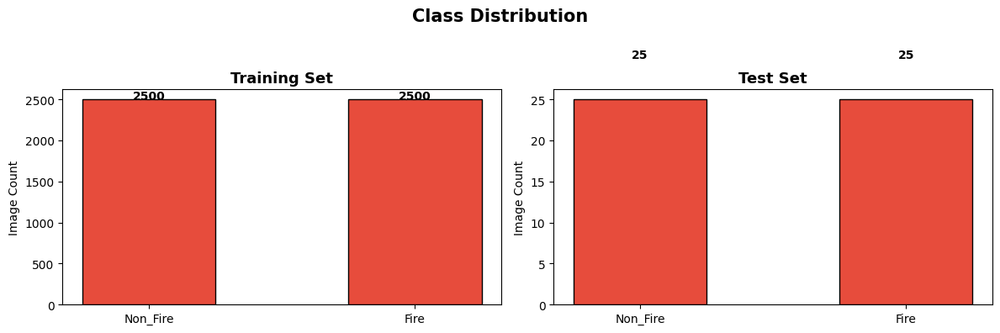

✅ Class distribution plotted.


In [ ]:
# ── Dynamically find train/test paths ─────────────────────────────────────
def find_split_dirs(root):
    """Return (train_dir, test_dir) by searching for 'fire' subfolders."""
    train_dir = test_dir = None
    for dirpath, dirnames, _ in os.walk(root):
        if 'fire' in dirnames or 'Fire' in dirnames:
            basename = os.path.basename(dirpath).lower()
            if 'train' in basename:
                train_dir = dirpath
            elif 'test' in basename or 'valid' in basename:
                test_dir = dirpath
    # Fallback: if no split folders, use root as train
    if train_dir is None:
        train_dir = root
    if test_dir is None:
        test_dir = root
    return train_dir, test_dir

# opendatasets names the folder after the dataset slug
DATASET_ROOT = '/content/wildfire'

TRAIN_DIR, TEST_DIR = find_split_dirs(DATASET_ROOT)
print(f"Train dir : {TRAIN_DIR}")
print(f"Test  dir : {TEST_DIR}")

# ── Count images per class ─────────────────────────────────────────────────
def count_images(split_dir):
    counts = {}
    for cls in os.listdir(split_dir):
        cls_path = os.path.join(split_dir, cls)
        if os.path.isdir(cls_path):
            exts = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
            counts[cls] = sum(1 for f in os.listdir(cls_path) if f.lower().endswith(exts))
    return counts

train_counts = count_images(TRAIN_DIR)
test_counts  = count_images(TEST_DIR)

print("\nTraining set distribution:", train_counts)
print("Test set distribution:    ", test_counts)

# ── Class distribution bar chart ──────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, counts, title in zip(axes,
                              [train_counts, test_counts],
                              ['Training Set', 'Test Set']):
    colors = ['#E74C3C' if 'fire' in k.lower() else '#2ECC71' for k in counts]
    ax.bar(counts.keys(), counts.values(), color=colors, edgecolor='black', width=0.5)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_ylabel('Image Count')
    for i, (k, v) in enumerate(counts.items()):
        ax.text(i, v + 5, str(v), ha='center', fontweight='bold')

plt.suptitle('Class Distribution', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Class distribution plotted.")

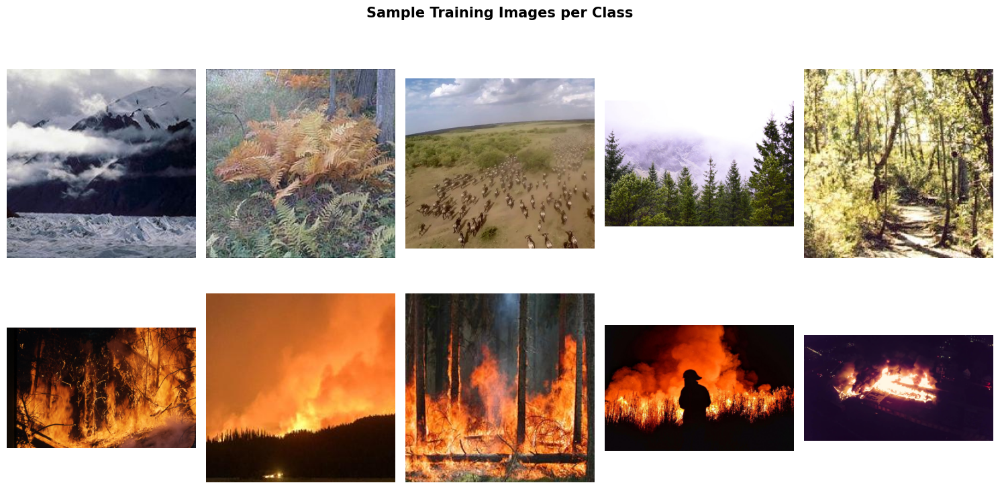

In [ ]:
# ── Display sample images from each class ─────────────────────────────────
def get_sample_images(split_dir, cls_name, n=5):
    cls_path = os.path.join(split_dir, cls_name)
    images = [f for f in os.listdir(cls_path)
              if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    samples = random.sample(images, min(n, len(images)))
    result = []
    for f in samples:
        full_path = os.path.join(cls_path, f)
        img = cv2.imread(full_path)
        if img is not None:
            result.append(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    return result

classes = list(train_counts.keys())
fig, axes = plt.subplots(len(classes), 5, figsize=(15, 4 * len(classes)))

# Normalize axes to always be 2D array
if len(classes) == 1:
    axes = [axes]  # wrap so axes[0] works
axes = [row if hasattr(row, '__len__') else [row] for row in axes]

for row_idx, cls in enumerate(classes):
    samples = get_sample_images(TRAIN_DIR, cls, n=5)
    for col_idx in range(5):
        ax = axes[row_idx][col_idx]
        if col_idx < len(samples):
            ax.imshow(samples[col_idx])
            if col_idx == 0:
                ax.set_ylabel(cls.upper(), fontsize=12, fontweight='bold',
                              rotation=90, labelpad=10)
        else:
            ax.axis('off')  # hide unused slots
        ax.axis('off')

plt.suptitle('Sample Training Images per Class', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/sample_images.png', dpi=150, bbox_inches='tight')
plt.show()

---
##  Section 3: Pre-processing
### 3.1 Outlier / Corrupt Image Detection

In [ ]:
# ── Step 1: Detect and remove corrupt / near-blank images ─────────────────
def detect_outlier_images(split_dir, brightness_thresh=10, blur_thresh=50):
    """
    Outlier criteria:
      - Corrupt: cannot be read by OpenCV
      - Too dark : mean pixel brightness < brightness_thresh
      - Too blurry: Laplacian variance < blur_thresh
    Returns list of (filepath, reason) tuples.
    """
    outliers = []
    total = 0
    for cls in os.listdir(split_dir):
        cls_path = os.path.join(split_dir, cls)
        if not os.path.isdir(cls_path):
            continue
        for fname in os.listdir(cls_path):
            if not fname.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
                continue
            fpath = os.path.join(cls_path, fname)
            total += 1
            img = cv2.imread(fpath)
            if img is None:
                outliers.append((fpath, 'corrupt'))
                continue
            gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
            brightness = gray.mean()
            blur_score = cv2.Laplacian(gray, cv2.CV_64F).var()
            if brightness < brightness_thresh:
                outliers.append((fpath, f'too_dark (brightness={brightness:.1f})'))
            elif blur_score < blur_thresh:
                outliers.append((fpath, f'too_blurry (laplacian={blur_score:.1f})'))
    return outliers, total

print("🔍 Scanning training set for outlier images...")
outliers, total_imgs = detect_outlier_images(TRAIN_DIR)
print(f"Total images scanned : {total_imgs}")
print(f"Outliers found       : {len(outliers)}")

if outliers:
    print("\nSample outliers:")
    for path, reason in outliers[:10]:
        print(f"  [{reason}] {os.path.basename(path)}")
    # Optional: remove outliers
    # for path, _ in outliers:
    #     os.remove(path)
    # print(f"Removed {len(outliers)} outlier images.")
else:
    print("✅ No significant outliers found — dataset is clean.")

🔍 Scanning training set for outlier images...
Total images scanned : 5000
Outliers found       : 679

Sample outliers:
  [too_blurry (laplacian=6.2)] NF_2324.jpg
  [too_blurry (laplacian=3.0)] NF_1844.jpg
  [too_blurry (laplacian=27.7)] NF_1848.jpg
  [too_blurry (laplacian=18.5)] NF_2410.jpg
  [too_blurry (laplacian=7.6)] NF_1683.jpg
  [too_blurry (laplacian=5.6)] NF_2288.jpg
  [too_blurry (laplacian=12.9)] NF_1751.jpg
  [too_blurry (laplacian=44.6)] NF_2096.jpg
  [too_blurry (laplacian=28.5)] NF_1943.jpg
  [too_blurry (laplacian=17.0)] NF_1749.jpg


In [ ]:
# ── Remove corrupt images that PIL cannot open ─────────────────────────────
from PIL import Image as PILImage

def remove_corrupt_images(split_dir):
    removed = 0
    for cls in os.listdir(split_dir):
        cls_path = os.path.join(split_dir, cls)
        if not os.path.isdir(cls_path):
            continue
        for fname in os.listdir(cls_path):
            if not fname.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
                continue
            fpath = os.path.join(cls_path, fname)
            try:
                with PILImage.open(fpath) as img:
                    img.verify()
            except Exception:
                os.remove(fpath)
                print(f"  🗑️  Removed (verify failed): {fname}")
                removed += 1
                continue
            try:
                with PILImage.open(fpath) as img:
                    img.convert('RGB')
            except Exception:
                os.remove(fpath)
                print(f"  🗑️  Removed (convert failed): {fname}")
                removed += 1

    print(f"✅ Done. Removed {removed} corrupt images from {split_dir}")

print("🔍 Cleaning TRAIN_DIR...")
remove_corrupt_images(TRAIN_DIR)
print("\n🔍 Cleaning TEST_DIR...")
remove_corrupt_images(TEST_DIR)

🔍 Cleaning TRAIN_DIR...
  🗑️  Removed (verify failed): F_763.jpg
  🗑️  Removed (verify failed): F_772.jpg
  🗑️  Removed (verify failed): F_744.jpg
  🗑️  Removed (verify failed): F_634.jpg
  🗑️  Removed (verify failed): F_912.jpg
  🗑️  Removed (verify failed): F_796.jpg
  🗑️  Removed (verify failed): F_598.jpg
  🗑️  Removed (verify failed): F_636.jpg
  🗑️  Removed (verify failed): F_835.jpg
  🗑️  Removed (verify failed): F_704.jpg
  🗑️  Removed (verify failed): F_790.jpg
  🗑️  Removed (verify failed): F_90.jpg
  🗑️  Removed (verify failed): F_661.jpg
  🗑️  Removed (verify failed): F_878.jpg
  🗑️  Removed (verify failed): F_767.jpg
  🗑️  Removed (verify failed): F_890.jpg
  🗑️  Removed (verify failed): F_654.jpg
  🗑️  Removed (verify failed): F_892.jpg
  🗑️  Removed (verify failed): F_646.jpg
  🗑️  Removed (verify failed): F_70.jpg
  🗑️  Removed (verify failed): F_700.jpg
  🗑️  Removed (verify failed): F_920.jpg
  🗑️  Removed (verify failed): F_748.jpg
  🗑️  Removed (verify failed): F_83

### 3.2 Class Imbalance — Sampling Strategy

Class names    : ['Fire', 'Non_Fire']
Class weights  : {0: np.float64(1.092136428233065), 1: np.float64(0.9222)}


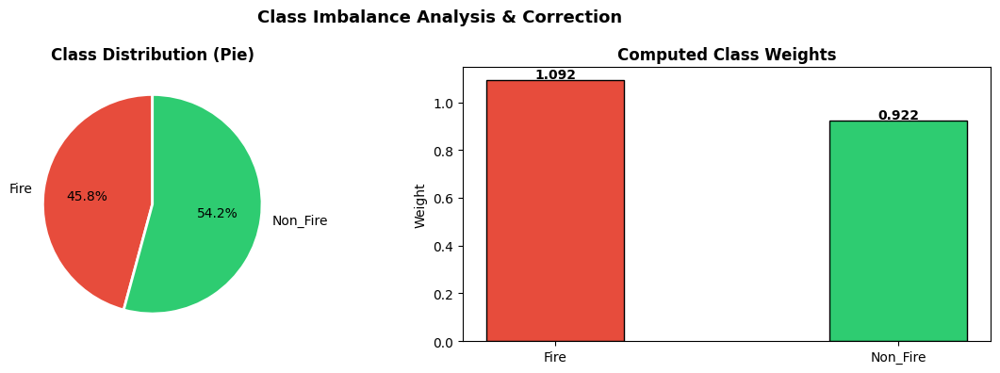

In [ ]:
# ── Step 2: Handle class imbalance via class weights (soft sampling) ───────
# This avoids physically duplicating/removing images while correcting bias.

all_labels = []
for cls_idx, cls in enumerate(sorted(os.listdir(TRAIN_DIR))):
    cls_path = os.path.join(TRAIN_DIR, cls)
    if not os.path.isdir(cls_path):
        continue
    n = sum(1 for f in os.listdir(cls_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png')))
    all_labels.extend([cls_idx] * n)

all_labels_arr = np.array(all_labels)
class_names    = sorted([d for d in os.listdir(TRAIN_DIR)
                          if os.path.isdir(os.path.join(TRAIN_DIR, d))])

class_weights_arr = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(all_labels_arr),
    y=all_labels_arr
)
CLASS_WEIGHTS = dict(enumerate(class_weights_arr))

print(f"Class names    : {class_names}")
print(f"Class weights  : {CLASS_WEIGHTS}")

# ── Imbalance ratio visualization ─────────────────────────────────────────
counter = Counter(all_labels_arr)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].pie([counter[i] for i in range(len(class_names))],
            labels=class_names, autopct='%1.1f%%',
            colors=['#E74C3C', '#2ECC71'], startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[0].set_title('Class Distribution (Pie)', fontweight='bold')

axes[1].bar(class_names, [CLASS_WEIGHTS[i] for i in range(len(class_names))],
            color=['#E74C3C', '#2ECC71'], edgecolor='black', width=0.4)
axes[1].set_title('Computed Class Weights', fontweight='bold')
axes[1].set_ylabel('Weight')
for i, w in enumerate(CLASS_WEIGHTS.values()):
    axes[1].text(i, w + 0.01, f'{w:.3f}', ha='center', fontweight='bold')

plt.suptitle('Class Imbalance Analysis & Correction', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/class_weights.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.3 Image Pre-processing Pipeline (Resize + Normalize + Augmentation)

In [ ]:
# ── Step 3: Build ImageDataGenerators ─────────────────────────────────────
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    horizontal_flip=True,
    vertical_flip=False,
    rotation_range=20,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    brightness_range=[0.7, 1.3],
    channel_shift_range=20.0,
    fill_mode='nearest',
    validation_split=0.2
)

val_test_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    validation_split=0.2
)

n_classes = len(class_names)
class_mode = 'binary' if n_classes == 2 else 'categorical'
print(f"Detected {n_classes} classes → class_mode = '{class_mode}'")

def make_generator(datagen, directory, subset=None, shuffle=True):
    kwargs = dict(
        directory=directory,
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode=class_mode,
        seed=SEED,
        shuffle=shuffle
    )
    if subset:
        kwargs['subset'] = subset
    # keep_aspect_ratio=False is default; PIL backend is used automatically
    return datagen.flow_from_directory(**kwargs)

train_gen = make_generator(train_datagen, TRAIN_DIR, subset='training')
val_gen   = make_generator(val_test_datagen, TRAIN_DIR, subset='validation')
test_gen  = make_generator(val_test_datagen, TEST_DIR, shuffle=False)

print(f"\nTraining samples  : {train_gen.samples}")
print(f"Validation samples: {val_gen.samples}")
print(f"Test samples      : {test_gen.samples}")
print(f"Class indices     : {train_gen.class_indices}")

Detected 2 classes → class_mode = 'binary'
Found 3689 images belonging to 2 classes.
Found 922 images belonging to 2 classes.
Found 50 images belonging to 2 classes.

Training samples  : 3689
Validation samples: 922
Test samples      : 50
Class indices     : {'Fire': 0, 'Non_Fire': 1}


Found 4611 images belonging to 2 classes.
Found 3689 images belonging to 2 classes.


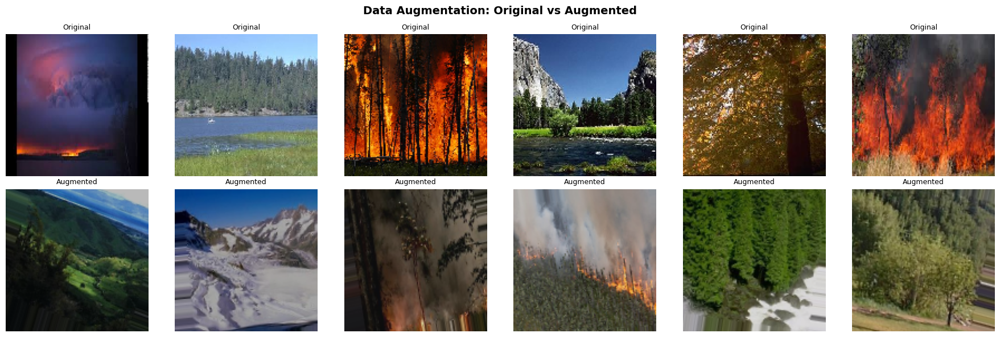

In [ ]:
# ── Visualize augmented vs original images ─────────────────────────────────
# Grab one batch of original images
orig_gen = ImageDataGenerator(rescale=1.0/255.0)
orig_iter = orig_gen.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=6,
    class_mode=class_mode, shuffle=True, seed=SEED
)
orig_batch, _ = next(orig_iter)

aug_iter = train_datagen.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=6,
    class_mode=class_mode, subset='training', shuffle=True, seed=SEED
)
aug_batch, _ = next(aug_iter)

fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for i in range(6):
    axes[0][i].imshow(np.clip(orig_batch[i], 0, 1))
    axes[0][i].axis('off')
    axes[0][i].set_title('Original', fontsize=9)
    axes[1][i].imshow(np.clip(aug_batch[i], 0, 1))
    axes[1][i].axis('off')
    axes[1][i].set_title('Augmented', fontsize=9)

plt.suptitle('Data Augmentation: Original vs Augmented', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/augmentation_preview.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 🏗️ Section 4: Model 1 — Custom Binary CNN

In [ ]:
# ── Determine output units & loss based on class mode ─────────────────────
OUTPUT_UNITS = 1 if class_mode == 'binary' else n_classes
OUTPUT_ACT   = 'sigmoid' if class_mode == 'binary' else 'softmax'
LOSS_FN      = 'binary_crossentropy' if class_mode == 'binary' else 'categorical_crossentropy'

# ── Build Custom CNN ───────────────────────────────────────────────────────
def build_custom_cnn(activation_hidden='relu',
                     dropout_rate=0.4,
                     l2_lambda=1e-4,
                     learning_rate=1e-3,
                     optimizer_name='adam'):
    """
    Custom CNN architecture.
    activation_hidden: 'relu' or 'elu' (two different activation functions)
    optimizer_name   : 'adam' or 'sgd'  (two different optimizers)
    """
    model = models.Sequential(name='Custom_CNN')
    # Block 1
    model.add(layers.Conv2D(32, (3,3), padding='same',
                             activation=activation_hidden,
                             kernel_regularizer=regularizers.l2(l2_lambda),
                             input_shape=(*IMG_SIZE, 3)))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2,2)))
    # Block 2
    model.add(layers.Conv2D(64, (3,3), padding='same',
                             activation=activation_hidden,
                             kernel_regularizer=regularizers.l2(l2_lambda)))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2,2)))
    model.add(layers.Dropout(dropout_rate / 2))
    # Block 3
    model.add(layers.Conv2D(128, (3,3), padding='same',
                              activation=activation_hidden,
                              kernel_regularizer=regularizers.l2(l2_lambda)))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2,2)))
    model.add(layers.Dropout(dropout_rate / 2))
    # Block 4
    model.add(layers.Conv2D(256, (3,3), padding='same',
                              activation=activation_hidden,
                              kernel_regularizer=regularizers.l2(l2_lambda)))
    model.add(layers.BatchNormalization())
    model.add(layers.GlobalAveragePooling2D())
    # Classifier head
    model.add(layers.Dense(256, activation=activation_hidden,
                            kernel_regularizer=regularizers.l2(l2_lambda)))
    model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(128, activation=activation_hidden))
    model.add(layers.Dropout(dropout_rate / 2))
    # ── Output layer — Sigmoid activation ─────────────────────────────────
    model.add(layers.Dense(OUTPUT_UNITS, activation=OUTPUT_ACT))

    # ── Optimizer selection ────────────────────────────────────────────────
    if optimizer_name == 'adam':
        opt = keras.optimizers.Adam(learning_rate=learning_rate)
    elif optimizer_name == 'sgd':
        opt = keras.optimizers.SGD(learning_rate=learning_rate,
                                    momentum=0.9, nesterov=True)
    else:
        opt = keras.optimizers.RMSprop(learning_rate=learning_rate)

    model.compile(optimizer=opt, loss=LOSS_FN,
                  metrics=['accuracy',
                           keras.metrics.Precision(name='precision'),
                           keras.metrics.Recall(name='recall'),
                           keras.metrics.AUC(name='auc')])
    return model

cnn_model = build_custom_cnn()
cnn_model.summary()

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 489,153 (1.87 MB)

 Trainable params: 488,193 (1.86 MB)

 Non-trainable params: 960 (3.75 KB)

### 4.1 Hyperparameter Tuning (Keras Tuner — RandomSearch)

In [ ]:
# ── Keras Tuner: HyperModel definition ────────────────────────────────────
def build_tuner_model(hp):
    """
    Hyperparameters searched:
      - filters_block1 : [32, 64]
      - dropout_rate   : [0.2, 0.4, 0.5]
      - learning_rate  : [1e-2, 1e-3, 1e-4]
      - optimizer      : ['adam', 'sgd']
      - activation     : ['relu', 'elu']
    """
    activation  = hp.Choice('activation', ['relu', 'elu'])
    dropout     = hp.Float('dropout_rate', min_value=0.2, max_value=0.5, step=0.1)
    lr          = hp.Choice('learning_rate', [1e-2, 1e-3, 1e-4])
    opt_name    = hp.Choice('optimizer', ['adam', 'sgd'])
    n_filters   = hp.Choice('filters_block1', [32, 64])
    l2_lambda   = hp.Choice('l2_lambda', [1e-3, 1e-4])

    model = models.Sequential(name='Tuner_CNN')
    model.add(layers.Conv2D(n_filters, (3,3), padding='same',
                             activation=activation,
                             kernel_regularizer=regularizers.l2(l2_lambda),
                             input_shape=(*IMG_SIZE, 3)))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2,2)))
    model.add(layers.Conv2D(n_filters*2, (3,3), padding='same',
                             activation=activation))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2,2)))
    model.add(layers.Conv2D(n_filters*4, (3,3), padding='same',
                             activation=activation))
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dense(128, activation=activation))
    model.add(layers.Dropout(dropout))
    model.add(layers.Dense(OUTPUT_UNITS, activation=OUTPUT_ACT))

    if opt_name == 'adam':
        opt = keras.optimizers.Adam(learning_rate=lr)
    else:
        opt = keras.optimizers.SGD(learning_rate=lr, momentum=0.9, nesterov=True)

    model.compile(optimizer=opt, loss=LOSS_FN,
                  metrics=['accuracy',
                           keras.metrics.Precision(name='precision'),
                           keras.metrics.Recall(name='recall')])
    return model

# ── Run Keras Tuner ────────────────────────────────────────────────────────
tuner = kt.RandomSearch(
    build_tuner_model,
    objective='val_accuracy',
    max_trials=10,
    executions_per_trial=1,
    directory='/content/kt_results',
    project_name='wildfire_cnn',
    overwrite=True,
    max_consecutive_failed_trials=5
)

tuner_callbacks = [
    callbacks.EarlyStopping(monitor='val_accuracy', patience=3,
                             restore_best_weights=True)
]

print("\n🔍 Starting Hyperparameter Search...")
tuner.search(
    train_gen,
    validation_data=val_gen,
    epochs=10,
    callbacks=tuner_callbacks,
    class_weight=CLASS_WEIGHTS
)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("\n✅ Best Hyperparameters Found:")
for param in ['activation', 'dropout_rate', 'learning_rate',
               'optimizer', 'filters_block1', 'l2_lambda']:
    print(f"   {param:20s}: {best_hps.get(param)}")

Trial 10 Complete [00h 04m 58s]
val_accuracy: 0.9436008930206299

Best val_accuracy So Far: 0.9479392766952515
Total elapsed time: 00h 43m 39s

✅ Best Hyperparameters Found:
   activation          : relu
   dropout_rate        : 0.2
   learning_rate       : 0.0001
   optimizer           : adam
   filters_block1      : 32
   l2_lambda           : 0.001


### 4.2 Train Custom CNN with Hyperparameters

In [ ]:
# ── Build the best CNN model from tuner results ────────────────────────────
best_cnn = build_custom_cnn(
    activation_hidden = best_hps.get('activation'),
    dropout_rate      = best_hps.get('dropout_rate'),
    l2_lambda         = best_hps.get('l2_lambda'),
    learning_rate     = best_hps.get('learning_rate'),
    optimizer_name    = best_hps.get('optimizer')
)

# ── Callbacks ─────────────────────────────────────────────────────────────
cnn_callbacks = [
    callbacks.EarlyStopping(
        monitor='val_loss', patience=7,
        restore_best_weights=True, verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=3, min_lr=1e-7, verbose=1
    ),
    callbacks.ModelCheckpoint(
        '/content/best_cnn.keras',
        monitor='val_accuracy', save_best_only=True, verbose=0
    )
]

print("🚀 Training Custom CNN (Model 1)...")
history_cnn = best_cnn.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_BASE,
    callbacks=cnn_callbacks,
    class_weight=CLASS_WEIGHTS,
    verbose=1
)

print("\n✅ Custom CNN training complete.")

🚀 Training Custom CNN (Model 1)...
Epoch 1/30
116/116 ━━━━━━━━━━━━━━━━━━━━ 46s 315ms/step - accuracy: 0.8696 - auc: 0.9440 - loss: 0.8545 - precision: 0.8646 - recall: 0.9005 - val_accuracy: 0.8731 - val_auc: 0.9494 - val_loss: 1.1554 - val_precision: 0.8553 - val_recall: 0.9220 - learning_rate: 1.0000e-04
Epoch 2/30
116/116 ━━━━━━━━━━━━━━━━━━━━ 29s 249ms/step - accuracy: 0.8994 - auc: 0.9645 - loss: 0.7762 - precision: 0.8967 - recall: 0.9205 - val_accuracy: 0.7722 - val_auc: 0.9539 - val_loss: 1.0106 - val_precision: 0.7077 - val_recall: 0.9880 - learning_rate: 1.0000e-04
Epoch 3/30
116/116 ━━━━━━━━━━━━━━━━━━━━ 29s 250ms/step - accuracy: 0.9198 - auc: 0.9725 - loss: 0.7277 - precision: 0.9218 - recall: 0.9310 - val_accuracy: 0.8742 - val_auc: 0.9530 - val_loss: 0.8033 - val_precision: 0.8542 - val_recall: 0.9260 - learning_rate: 1.0000e-04
Epoch 4/30
116/116 ━━━━━━━━━━━━━━━━━━━━ 29s 251ms/step - accuracy: 0.9252 - auc: 0.9757 - loss: 0.6978 - precision: 0.9246 - recall: 0.9385 - val_

In [ ]:
# ── Optimizer comparison: retrain with SGD ─────────────────────────────────
# This directly compares the two optimizers
print("🔄 Training CNN variant with SGD optimizer for comparison...")

sgd_cnn = build_custom_cnn(
    activation_hidden = best_hps.get('activation'),
    dropout_rate      = best_hps.get('dropout_rate'),
    l2_lambda         = best_hps.get('l2_lambda'),
    learning_rate     = 1e-3,
    optimizer_name    = 'sgd'   # ← SGD with Nesterov momentum
)

sgd_callbacks = [
    callbacks.EarlyStopping(monitor='val_loss', patience=7,
                             restore_best_weights=True)
]

history_sgd = sgd_cnn.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_BASE,
    callbacks=sgd_callbacks,
    class_weight=CLASS_WEIGHTS,
    verbose=0  # silent
)
print("✅ SGD CNN training complete.")

🔄 Training CNN variant with SGD optimizer for comparison...
✅ SGD CNN training complete.


  Augmentation Ablation Study

[1/3] Training: No Augmentation...
Found 3689 images belonging to 2 classes.
Found 922 images belonging to 2 classes.
[2/3] Training: Geometric Augmentation Only...
Found 3689 images belonging to 2 classes.
Found 922 images belonging to 2 classes.
[3/3] Using already-trained full augmentation model (best_cnn)...

📊 Ablation Study Results:
           Augmentation  accuracy  precision  recall     f1
                   None      0.88     0.8519    0.92 0.8846
         Geometric Only      0.94     0.9583    0.92 0.9388
Geometric + Photometric      0.96     0.9259    1.00 0.9615


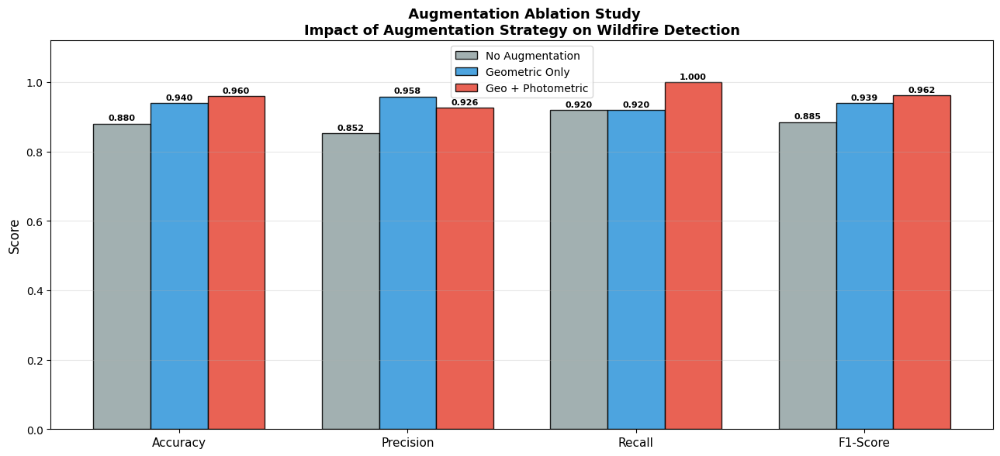

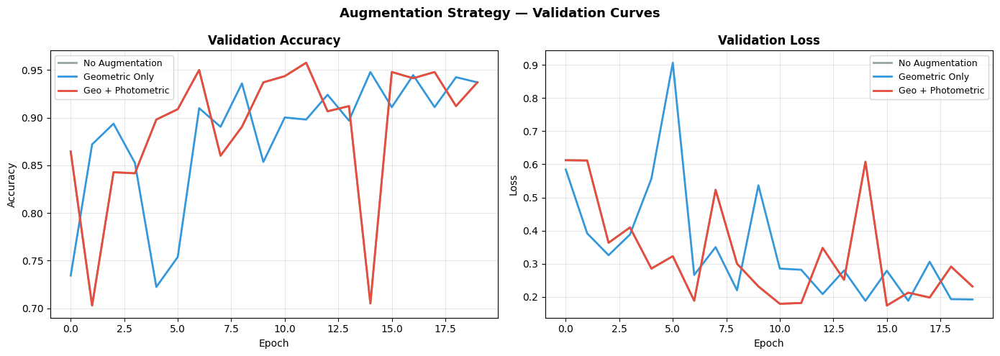

✅ Augmentation Ablation Study complete.


In [ ]:
# We train 3 versions of the CNN to measure the impact of augmentation:
#   Version A — No augmentation
#   Version B — Geometric augmentation only
#   Version C — Geometric + Photometric augmentation (full)
# ══════════════════════════════════════════════════════════════════════════
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os
import tensorflow as tf

# Suppress TF retracing warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
tf.get_logger().setLevel('ERROR')

print("=" * 60)
print("  Augmentation Ablation Study")
print("=" * 60)

ablation_results = []

# ── Version A: No Augmentation ────────────────────────────────────────────
print("\n[1/3] Training: No Augmentation...")
gen_none = ImageDataGenerator(rescale=1.0/255.0, validation_split=0.2)
train_none = gen_none.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode=class_mode, subset='training', seed=SEED)
val_none = gen_none.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode=class_mode, subset='validation', seed=SEED)

model_none = build_custom_cnn()
cb_none = [callbacks.EarlyStopping(monitor='val_loss', patience=5,
                                    restore_best_weights=True)]
hist_none = model_none.fit(train_none, validation_data=val_none,
                            epochs=20, callbacks=cb_none,
                            class_weight=CLASS_WEIGHTS, verbose=0)

# ── Version B: Geometric Augmentation Only ────────────────────────────────
print("[2/3] Training: Geometric Augmentation Only...")
gen_geo = ImageDataGenerator(
    rescale=1.0/255.0,
    horizontal_flip=True,
    rotation_range=20,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    validation_split=0.2
)
train_geo = gen_geo.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode=class_mode, subset='training', seed=SEED)
val_geo = gen_geo.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode=class_mode, subset='validation', seed=SEED)

model_geo = build_custom_cnn()
cb_geo = [callbacks.EarlyStopping(monitor='val_loss', patience=5,
                                   restore_best_weights=True)]
hist_geo = model_geo.fit(train_geo, validation_data=val_geo,
                          epochs=20, callbacks=cb_geo,
                          class_weight=CLASS_WEIGHTS, verbose=0)

# ── Version C: Geometric + Photometric (Full — already trained as best_cnn)
print("[3/3] Using already-trained full augmentation model (best_cnn)...")

# ── Evaluate all 3 on test set ─────────────────────────────────────────────
def quick_eval(model, gen):
    gen.reset()
    preds = model.predict(gen, verbose=0)
    y_true = gen.classes
    if class_mode == 'binary':
        y_pred = (preds.ravel() > 0.5).astype(int)
    else:
        y_pred = np.argmax(preds, axis=1)
    return {
        'accuracy' : round(accuracy_score(y_true, y_pred), 4),
        'precision': round(precision_score(y_true, y_pred, zero_division=0), 4),
        'recall'   : round(recall_score(y_true, y_pred, zero_division=0), 4),
        'f1'       : round(f1_score(y_true, y_pred, zero_division=0), 4)
    }

test_gen.reset(); r_none = quick_eval(model_none, test_gen)
test_gen.reset(); r_geo  = quick_eval(model_geo,  test_gen)
test_gen.reset(); r_full = quick_eval(best_cnn,   test_gen)

ablation_df = pd.DataFrame([
    {'Augmentation': 'None',                      **r_none},
    {'Augmentation': 'Geometric Only',             **r_geo},
    {'Augmentation': 'Geometric + Photometric',    **r_full},
])

print("\n📊 Ablation Study Results:")
print(ablation_df.to_string(index=False))

# ── Plot ablation results ──────────────────────────────────────────────────
metrics   = ['accuracy', 'precision', 'recall', 'f1']
x         = np.arange(len(metrics))
width     = 0.25
fig, ax   = plt.subplots(figsize=(13, 6))
colors    = ['#95A5A6', '#3498DB', '#E74C3C']
labels    = ['No Augmentation', 'Geometric Only', 'Geo + Photometric']

for i, (row, color, label) in enumerate(zip(ablation_df.itertuples(), colors, labels)):
    vals = [row.accuracy, row.precision, row.recall, row.f1]
    bars = ax.bar(x + i * width, vals, width, label=label,
                  color=color, edgecolor='black', alpha=0.88)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_xticks(x + width)
ax.set_xticklabels(['Accuracy', 'Precision', 'Recall', 'F1-Score'], fontsize=11)
ax.set_ylim(0, 1.12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title(' Augmentation Ablation Study\n'
             'Impact of Augmentation Strategy on Wildfire Detection',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('/content/ablation_study.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Plot training curves comparison ───────────────────────────────────────
# Use hist_full if available, otherwise fall back to hist_none for the curve
hist_full = getattr(best_cnn, '_training_history', None)  # set this if you saved it

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for hist, label, color in zip(
        [hist_none, hist_geo, hist_full if hist_full is not None else hist_none],
        labels, colors):
    h = hist.history if hasattr(hist, 'history') else hist
    axes[0].plot(h['val_accuracy'], label=label, color=color, lw=2)
    axes[1].plot(h['val_loss'],     label=label, color=color, lw=2)

for ax, title, ylabel in zip(axes,
                               ['Validation Accuracy', 'Validation Loss'],
                               ['Accuracy', 'Loss']):
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

plt.suptitle('Augmentation Strategy — Validation Curves', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/ablation_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Augmentation Ablation Study complete.")

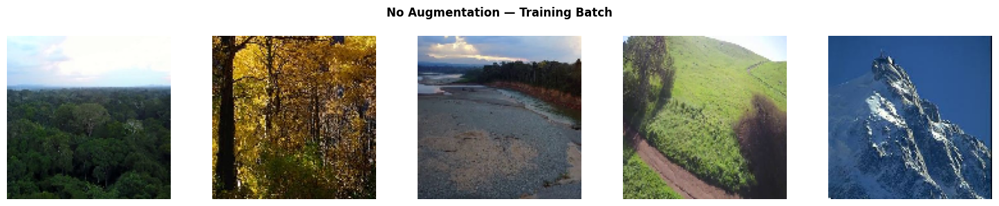

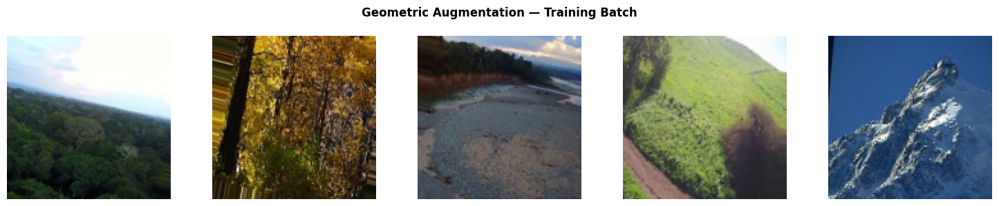

In [ ]:
# ── Sanity check: visualise one batch from each generator ─────────────────
import matplotlib.pyplot as plt

def show_batch(generator, title, n=5):
    generator.reset()
    imgs, labels = next(generator)
    fig, axes = plt.subplots(1, n, figsize=(15, 3))
    for i in range(n):
        axes[i].imshow(imgs[i])
        axes[i].axis('off')
    plt.suptitle(title, fontweight='bold')
    plt.tight_layout()
    plt.show()

show_batch(train_none, 'No Augmentation — Training Batch')
show_batch(train_geo,  'Geometric Augmentation — Training Batch')

In [ ]:
best_cnn.save('/content/custom_cnn_final.keras')
sgd_cnn.save('/content/sgd_cnn_final.keras')

free_model_memory(best_cnn, sgd_cnn)

✅ Memory freed — session cleared.


---
## Section 5: Model 2 — MobileNetV2 Transfer Learning

In [ ]:
# ── Build MobileNetV2 Transfer Learning model ──────────────────────────────
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2, ResNet50V2, EfficientNetB3

# ── Define required global variables (EDIT if needed) ─────────────────────
IMG_SIZE = (128, 128)       # Change if needed
OUTPUT_UNITS = 1             # 1 for binary, >1 for multi-class
OUTPUT_ACT = 'sigmoid'       # 'sigmoid' for binary, 'softmax' for multi-class
LOSS_FN = 'binary_crossentropy'  # change to 'categorical_crossentropy' if needed


# ── Build MobileNetV2 Transfer Learning model ──────────────────────────────
def build_mobilenet_model(
        learning_rate=1e-4,
        dropout_rate=0.3,
        activation_hidden='relu',
        optimizer_name='adam',
        fine_tune_at=100):

    # Load pretrained backbone
    base_model = MobileNetV2(
        input_shape=(*IMG_SIZE, 3),
        include_top=False,
        weights='imagenet'
    )

    base_model.trainable = False  # Freeze backbone initially

    # Custom classification head
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation=activation_hidden)(x)
    x = layers.Dropout(dropout_rate)(x)
    x = layers.Dense(128, activation=activation_hidden)(x)
    x = layers.Dropout(dropout_rate / 2)(x)
    outputs = layers.Dense(OUTPUT_UNITS, activation=OUTPUT_ACT)(x)

    model = keras.Model(inputs, outputs, name='MobileNetV2_TL')

    # Optimizer
    if optimizer_name == 'adam':
        optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    else:
        optimizer = keras.optimizers.SGD(
            learning_rate=learning_rate,
            momentum=0.9,
            nesterov=True
        )

    # Compile
    model.compile(
        optimizer=optimizer,
        loss=LOSS_FN,
        metrics=[
            'accuracy',
            keras.metrics.Precision(name='precision'),
            keras.metrics.Recall(name='recall'),
            keras.metrics.AUC(name='auc')
        ]
    )

    return model, base_model


# ── Build Model (No best_hps needed) ───────────────────────────────────────
mobilenet_model, mobilenet_base = build_mobilenet_model(
    activation_hidden='relu',
    dropout_rate=0.3,
    learning_rate=1e-4,
    optimizer_name='adam'
)

mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "MobileNetV2_TL"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,618,945 (9.99 MB)

 Trainable params: 360,961 (1.38 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# ── Phase 1: Train head only ───────────────────────────────────────────────
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

tl_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        '/content/best_mobilenet.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

print('🚀 Phase 1: Training MobileNetV2 head (backbone frozen)...')
history_tl_phase1 = mobilenet_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=15,
    callbacks=tl_callbacks,
    class_weight=CLASS_WEIGHTS
)
print('✅ Phase 1 complete.')


🚀 Phase 1: Training MobileNetV2 head (backbone frozen)...
Epoch 1/15
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 327ms/step - accuracy: 0.7450 - auc: 0.8138 - loss: 0.5170 - precision: 0.7568 - recall: 0.8074
Epoch 1: val_accuracy improved from None to 0.91432, saving model to /content/best_mobilenet.keras

Epoch 1: finished saving model to /content/best_mobilenet.keras
116/116 ━━━━━━━━━━━━━━━━━━━━ 76s 502ms/step - accuracy: 0.8433 - auc: 0.9245 - loss: 0.3607 - precision: 0.8492 - recall: 0.8645 - val_accuracy: 0.9143 - val_auc: 0.9706 - val_loss: 0.2323 - val_precision: 0.9488 - val_recall: 0.8900 - learning_rate: 1.0000e-04
Epoch 2/15
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step - accuracy: 0.9357 - auc: 0.9794 - loss: 0.1812 - precision: 0.9470 - recall: 0.9335
Epoch 2: val_accuracy improved from 0.91432 to 0.92842, saving model to /content/best_mobilenet.keras

Epoch 2: finished saving model to /content/best_mobilenet.keras
116/116 ━━━━━━━━━━━━━━━━━━━━ 30s 263ms/step - accuracy: 0.9406 - auc: 0

In [ ]:
# ── Phase 2: Fine-tune — unfreeze top layers of backbone ──────────────────
FINE_TUNE_AT = 100  # unfreeze from layer 100 onwards
mobilenet_base.trainable = True
for layer in mobilenet_base.layers[:FINE_TUNE_AT]:
    layer.trainable = False

# Recompile with a lower learning rate for fine-tuning
mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=2e-5),
    loss=LOSS_FN,
    metrics=[
        'accuracy',
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
        keras.metrics.AUC(name='auc')
    ]
)

print(f'🚀 Phase 2: Fine-tuning MobileNetV2 from layer {FINE_TUNE_AT}...')
history_tl_phase2 = mobilenet_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_TL,
    callbacks=tl_callbacks,
    class_weight=CLASS_WEIGHTS
)
print('✅ Phase 2 complete.')

# ── Merge Phase 1 + Phase 2 histories for plotting ────────────────────────
def merge_histories(h1, h2):
    merged = {}
    for key in h1.history:
        merged[key] = h1.history[key] + h2.history.get(key, [])
    return merged

history_tl_merged = merge_histories(history_tl_phase1, history_tl_phase2)
print('✅ Histories merged.')


🚀 Phase 2: Fine-tuning MobileNetV2 from layer 100...
Epoch 1/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - accuracy: 0.9252 - auc: 0.9800 - loss: 0.1862 - precision: 0.9144 - recall: 0.9496
Epoch 1: val_accuracy did not improve from 0.94469
116/116 ━━━━━━━━━━━━━━━━━━━━ 71s 418ms/step - accuracy: 0.9385 - auc: 0.9847 - loss: 0.1557 - precision: 0.9417 - recall: 0.9450 - val_accuracy: 0.9403 - val_auc: 0.9784 - val_loss: 0.2055 - val_precision: 0.9304 - val_recall: 0.9620 - learning_rate: 2.0000e-05
Epoch 2/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step - accuracy: 0.9571 - auc: 0.9876 - loss: 0.1322 - precision: 0.9548 - recall: 0.9669
Epoch 2: ReduceLROnPlateau reducing learning rate to 9.999999747378752e-06.

Epoch 2: val_accuracy improved from 0.94469 to 0.94685, saving model to /content/best_mobilenet.keras

Epoch 2: finished saving model to /content/best_mobilenet.keras
116/116 ━━━━━━━━━━━━━━━━━━━━ 31s 267ms/step - accuracy: 0.9623 - auc: 0.9917 - loss: 0.1092 - precision: 0.9627 

In [ ]:
mobilenet_model.save('/content/mobilenet_tl_final.keras')

free_model_memory(mobilenet_model, mobilenet_base)

✅ Memory freed — session cleared.


In [ ]:
# ══════════════════════════════════════════════════════════════════════════
# Section 5B: Model 3 — ResNet50V2 Transfer Learning
# ResNet50V2 uses pre-activation residual connections (He et al., 2016)
# Well-suited for detecting fine-grained fire textures and color patterns
# ══════════════════════════════════════════════════════════════════════════
from tensorflow.keras.applications import ResNet50V2

def build_resnet_model(learning_rate=1e-4, dropout_rate=0.3,
                       activation_hidden='relu', optimizer_name='adam'):

    base_model = ResNet50V2(
        input_shape=(*IMG_SIZE, 3),
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False  # Freeze backbone initially

    inputs  = keras.Input(shape=(*IMG_SIZE, 3))
    x       = base_model(inputs, training=False)
    x       = layers.GlobalAveragePooling2D()(x)
    x       = layers.Dense(256, activation=activation_hidden)(x)
    x       = layers.BatchNormalization()(x)
    x       = layers.Dropout(dropout_rate)(x)
    x       = layers.Dense(128, activation=activation_hidden)(x)
    x       = layers.Dropout(dropout_rate / 2)(x)
    outputs = layers.Dense(OUTPUT_UNITS, activation=OUTPUT_ACT)(x)

    model = keras.Model(inputs, outputs, name='ResNet50V2_TL')

    if optimizer_name == 'adam':
        optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    else:
        optimizer = keras.optimizers.SGD(learning_rate=learning_rate,
                                         momentum=0.9, nesterov=True)

    model.compile(
        optimizer=optimizer,
        loss=LOSS_FN,
        metrics=['accuracy',
                 keras.metrics.Precision(name='precision'),
                 keras.metrics.Recall(name='recall'),
                 keras.metrics.AUC(name='auc')]
    )
    return model, base_model


resnet_model, resnet_base = build_resnet_model(
    activation_hidden='relu', dropout_rate=0.3,
    learning_rate=1e-4, optimizer_name='adam'
)
resnet_model.summary()

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step


Model: "ResNet50V2_TL"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 4, 4, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,123,393 (92.02 MB)

 Trainable params: 558,081 (2.13 MB)

 Non-trainable params: 23,565,312 (89.89 MB)

In [ ]:
# ── Phase 1: Train ResNet50V2 head only ───────────────────────────────────
resnet_callbacks = [
    callbacks.EarlyStopping(monitor='val_loss', patience=5,
                             restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                 patience=3, min_lr=1e-7, verbose=1),
    callbacks.ModelCheckpoint('/content/best_resnet.keras',
                               monitor='val_accuracy', save_best_only=True, verbose=0)
]

print('🚀 Phase 1: Training ResNet50V2 head...')
history_resnet_phase1 = resnet_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_TL,
    callbacks=resnet_callbacks,
    class_weight=CLASS_WEIGHTS
)
print('✅ ResNet50V2 Phase 1 complete.')



🚀 Phase 1: Training ResNet50V2 head...
Epoch 1/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 57s 383ms/step - accuracy: 0.8241 - auc: 0.9143 - loss: 0.3728 - precision: 0.8572 - recall: 0.8105 - val_accuracy: 0.9013 - val_auc: 0.9535 - val_loss: 0.2804 - val_precision: 0.9082 - val_recall: 0.9100 - learning_rate: 1.0000e-04
Epoch 2/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 31s 265ms/step - accuracy: 0.9271 - auc: 0.9761 - loss: 0.1951 - precision: 0.9274 - recall: 0.9390 - val_accuracy: 0.9176 - val_auc: 0.9624 - val_loss: 0.2376 - val_precision: 0.9206 - val_recall: 0.9280 - learning_rate: 1.0000e-04
Epoch 3/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 31s 266ms/step - accuracy: 0.9355 - auc: 0.9811 - loss: 0.1708 - precision: 0.9353 - recall: 0.9465 - val_accuracy: 0.9187 - val_auc: 0.9686 - val_loss: 0.2191 - val_precision: 0.9225 - val_recall: 0.9280 - learning_rate: 1.0000e-04
Epoch 4/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 31s 268ms/step - accuracy: 0.9431 - auc: 0.9853 - loss: 0.1513 - precision: 0.9462 - recall: 0.9490 - 

In [ ]:
# ── Phase 2: Fine-tune top layers ─────────────────────────────────────────
RESNET_FINE_TUNE_AT = 150  # ResNet50V2 has ~190 layers; unfreeze top ~40
resnet_base.trainable = True
for layer in resnet_base.layers[:RESNET_FINE_TUNE_AT]:
    layer.trainable = False

resnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=2e-5),
    loss=LOSS_FN,
    metrics=['accuracy',
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall'),
             keras.metrics.AUC(name='auc')]
)

print(f'🚀 Phase 2: Fine-tuning ResNet50V2 from layer {RESNET_FINE_TUNE_AT}...')
history_resnet_phase2 = resnet_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_TL,
    callbacks=resnet_callbacks,
    class_weight=CLASS_WEIGHTS
)
print('✅ ResNet50V2 Phase 2 complete.')

history_resnet_merged = merge_histories(history_resnet_phase1, history_resnet_phase2)
print('✅ ResNet50V2 histories merged.')

🚀 Phase 2: Fine-tuning ResNet50V2 from layer 150...
Epoch 1/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 64s 379ms/step - accuracy: 0.9385 - auc: 0.9838 - loss: 0.1603 - precision: 0.9435 - recall: 0.9430 - val_accuracy: 0.9306 - val_auc: 0.9715 - val_loss: 0.2207 - val_precision: 0.9160 - val_recall: 0.9600 - learning_rate: 2.0000e-05
Epoch 2/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 31s 264ms/step - accuracy: 0.9477 - auc: 0.9874 - loss: 0.1399 - precision: 0.9488 - recall: 0.9550 - val_accuracy: 0.9360 - val_auc: 0.9721 - val_loss: 0.2182 - val_precision: 0.9265 - val_recall: 0.9580 - learning_rate: 2.0000e-05
Epoch 3/20
115/116 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - accuracy: 0.9667 - auc: 0.9933 - loss: 0.0975 - precision: 0.9703 - recall: 0.9676
Epoch 3: ReduceLROnPlateau reducing learning rate to 9.999999747378752e-06.
116/116 ━━━━━━━━━━━━━━━━━━━━ 30s 262ms/step - accuracy: 0.9686 - auc: 0.9936 - loss: 0.0951 - precision: 0.9701 - recall: 0.9720 - val_accuracy: 0.9414 - val_auc: 0.9758 - val_loss: 0.202

In [ ]:
resnet_model.save('/content/resnet50v2_tl_final.keras')

free_model_memory(resnet_model, resnet_base)

✅ Memory freed — session cleared.


In [ ]:
# ══════════════════════════════════════════════════════════════════════════
# Section 5D: Model 5 — EfficientNetB3 Transfer Learning
# EfficientNet scales depth/width/resolution jointly (Tan & Le, 2019)
# B3 variant offers strong accuracy with reasonable compute cost
# Note: EfficientNet expects inputs in [0, 255] range — no rescaling needed
# ══════════════════════════════════════════════════════════════════════════
from tensorflow.keras.applications import EfficientNetB3

# EfficientNetB3 requires 300x300 minimum but works fine at 128x128
def build_efficientnet_model(learning_rate=1e-4, dropout_rate=0.3,
                              activation_hidden='relu', optimizer_name='adam'):

    base_model = EfficientNetB3(
        input_shape=(*IMG_SIZE, 3),
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False

    inputs  = keras.Input(shape=(*IMG_SIZE, 3))
    # EfficientNet has built-in rescaling, so pass raw [0,1] pixels directly
    x       = base_model(inputs, training=False)
    x       = layers.GlobalAveragePooling2D()(x)
    x       = layers.Dense(256, activation=activation_hidden)(x)
    x       = layers.BatchNormalization()(x)
    x       = layers.Dropout(dropout_rate)(x)
    x       = layers.Dense(128, activation=activation_hidden)(x)
    x       = layers.Dropout(dropout_rate / 2)(x)
    outputs = layers.Dense(OUTPUT_UNITS, activation=OUTPUT_ACT)(x)

    model = keras.Model(inputs, outputs, name='EfficientNetB3_TL')

    if optimizer_name == 'adam':
        optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    else:
        optimizer = keras.optimizers.SGD(learning_rate=learning_rate,
                                         momentum=0.9, nesterov=True)

    model.compile(
        optimizer=optimizer,
        loss=LOSS_FN,
        metrics=['accuracy',
                 keras.metrics.Precision(name='precision'),
                 keras.metrics.Recall(name='recall'),
                 keras.metrics.AUC(name='auc')]
    )
    return model, base_model


efficientnet_model, efficientnet_base = build_efficientnet_model(
    activation_hidden='relu', dropout_rate=0.3,
    learning_rate=1e-4, optimizer_name='adam'
)
efficientnet_model.summary()

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "EfficientNetB3_TL"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb3 (Functional)     │ (None, 4, 4, 1536)     │    10,783,535 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1536)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       393,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,211,056 (42.77 MB)

 Trainable params: 427,009 (1.63 MB)

 Non-trainable params: 10,784,047 (41.14 MB)

In [ ]:
# ── Phase 1: Train EfficientNetB3 head only ───────────────────────────────
efficientnet_callbacks = [
    callbacks.EarlyStopping(monitor='val_loss', patience=5,
                             restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                 patience=3, min_lr=1e-7, verbose=1),
    callbacks.ModelCheckpoint('/content/best_efficientnet.keras',
                               monitor='val_accuracy', save_best_only=True, verbose=0)
]

print('🚀 Phase 1: Training EfficientNetB3 head...')
history_effnet_phase1 = efficientnet_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_TL,
    callbacks=efficientnet_callbacks,
    class_weight=CLASS_WEIGHTS
)
print('✅ EfficientNetB3 Phase 1 complete.')



🚀 Phase 1: Training EfficientNetB3 head...
Epoch 1/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 116s 664ms/step - accuracy: 0.5625 - auc: 0.5879 - loss: 0.6990 - precision: 0.6088 - recall: 0.5400 - val_accuracy: 0.7603 - val_auc: 0.8480 - val_loss: 0.6762 - val_precision: 0.8298 - val_recall: 0.7020 - learning_rate: 1.0000e-04
Epoch 2/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 30s 262ms/step - accuracy: 0.5820 - auc: 0.6196 - loss: 0.6794 - precision: 0.6227 - recall: 0.5810 - val_accuracy: 0.5889 - val_auc: 0.8538 - val_loss: 0.6632 - val_precision: 0.8954 - val_recall: 0.2740 - learning_rate: 1.0000e-04
Epoch 3/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 30s 257ms/step - accuracy: 0.5964 - auc: 0.6341 - loss: 0.6713 - precision: 0.6417 - recall: 0.5785 - val_accuracy: 0.7310 - val_auc: 0.8638 - val_loss: 0.6278 - val_precision: 0.8913 - val_recall: 0.5740 - learning_rate: 1.0000e-04
Epoch 4/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 30s 260ms/step - accuracy: 0.6023 - auc: 0.6500 - loss: 0.6633 - precision: 0.6493 - recall: 0.57

In [ ]:


# ── Phase 2: Fine-tune top blocks ─────────────────────────────────────────
EFFNET_FINE_TUNE_AT = 200  # EfficientNetB3 has ~384 layers; unfreeze top blocks
efficientnet_base.trainable = True
for layer in efficientnet_base.layers[:EFFNET_FINE_TUNE_AT]:
    layer.trainable = False

efficientnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=2e-5),
    loss=LOSS_FN,
    metrics=['accuracy',
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall'),
             keras.metrics.AUC(name='auc')]
)

print(f'🚀 Phase 2: Fine-tuning EfficientNetB3 from layer {EFFNET_FINE_TUNE_AT}...')
history_effnet_phase2 = efficientnet_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_TL,
    callbacks=efficientnet_callbacks,
    class_weight=CLASS_WEIGHTS
)
print('✅ EfficientNetB3 Phase 2 complete.')

history_effnet_merged = merge_histories(history_effnet_phase1, history_effnet_phase2)
print('✅ EfficientNetB3 histories merged.')

🚀 Phase 2: Fine-tuning EfficientNetB3 from layer 200...
Epoch 1/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 147s 674ms/step - accuracy: 0.6088 - auc: 0.6500 - loss: 0.7328 - precision: 0.6419 - recall: 0.6300 - val_accuracy: 0.4501 - val_auc: 0.2708 - val_loss: 1.5687 - val_precision: 0.3158 - val_recall: 0.0120 - learning_rate: 2.0000e-05
Epoch 2/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 31s 264ms/step - accuracy: 0.6750 - auc: 0.7367 - loss: 0.6448 - precision: 0.7150 - recall: 0.6660 - val_accuracy: 0.3297 - val_auc: 0.2933 - val_loss: 1.2872 - val_precision: 0.2748 - val_recall: 0.1440 - learning_rate: 2.0000e-05
Epoch 3/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step - accuracy: 0.7187 - auc: 0.7977 - loss: 0.5628 - precision: 0.7633 - recall: 0.7082
Epoch 3: ReduceLROnPlateau reducing learning rate to 9.999999747378752e-06.
116/116 ━━━━━━━━━━━━━━━━━━━━ 30s 259ms/step - accuracy: 0.7151 - auc: 0.7932 - loss: 0.5676 - precision: 0.7475 - recall: 0.7165 - val_accuracy: 0.7636 - val_auc: 0.8029 - val_loss: 

In [ ]:
efficientnet_model.save('/content/efficientnetb3_tl_final.keras')

free_model_memory(efficientnet_model, efficientnet_base)

✅ Memory freed — session cleared.


---
## 📊 Section 6: Training History Visualization

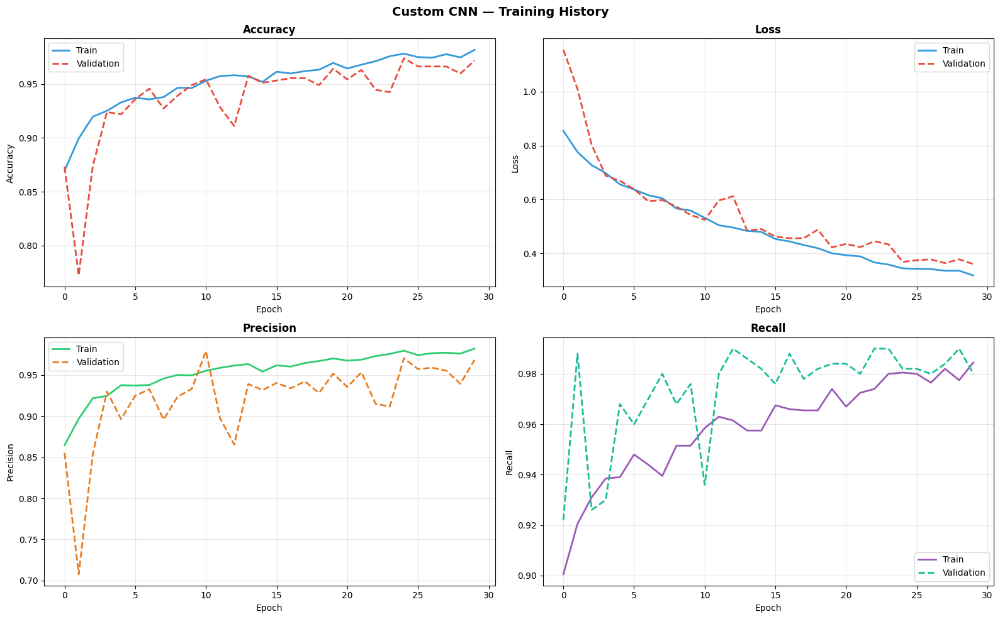

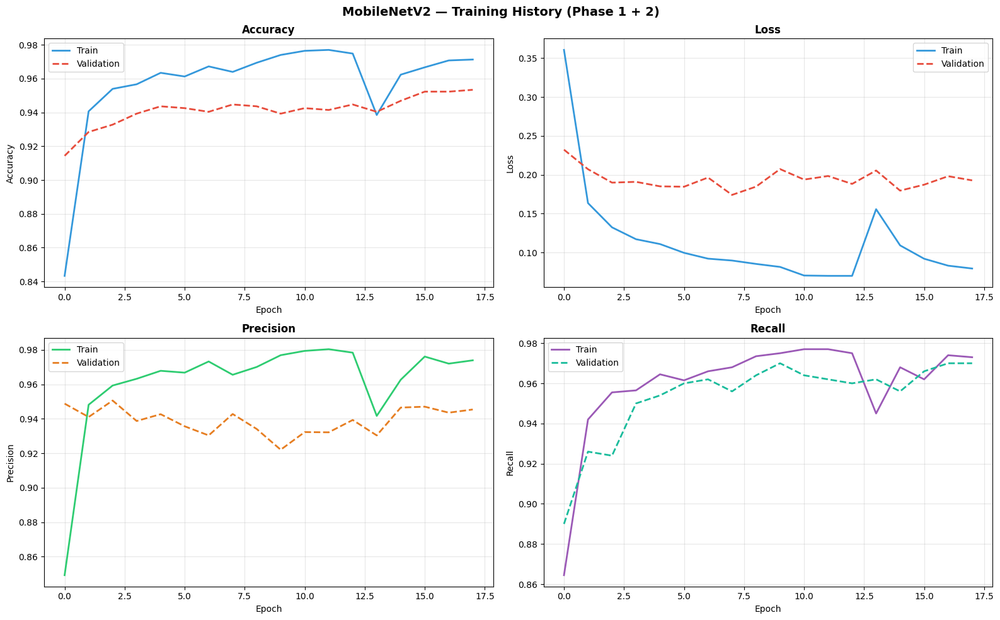

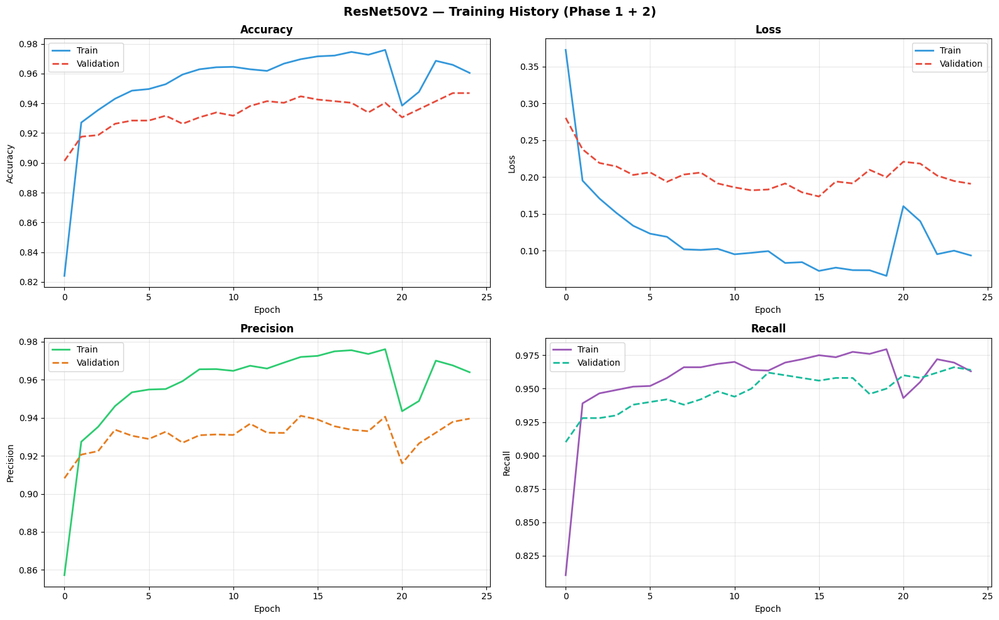

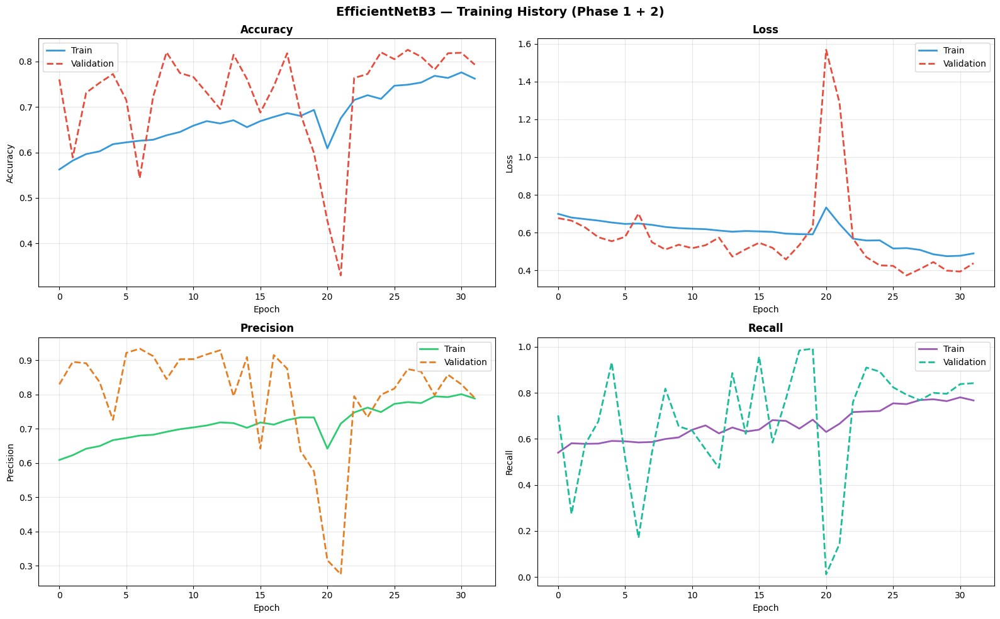

In [ ]:
def plot_training_history(history, title='Training History', save_path=None):
    hist = history.history if hasattr(history, 'history') else history
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))

    # ── Accuracy ──────────────────────────────────────────────────────────
    axes[0][0].plot(hist['accuracy'], label='Train', color='#3498DB', lw=2)
    axes[0][0].plot(hist['val_accuracy'], label='Validation',
                    color='#E74C3C', lw=2, linestyle='--')
    axes[0][0].set_title('Accuracy', fontweight='bold')
    axes[0][0].set_xlabel('Epoch')
    axes[0][0].set_ylabel('Accuracy')
    axes[0][0].legend()
    axes[0][0].grid(alpha=0.3)

    # ── Loss ──────────────────────────────────────────────────────────────
    axes[0][1].plot(hist['loss'], label='Train', color='#3498DB', lw=2)
    axes[0][1].plot(hist['val_loss'], label='Validation',
                    color='#E74C3C', lw=2, linestyle='--')
    axes[0][1].set_title('Loss', fontweight='bold')
    axes[0][1].set_xlabel('Epoch')
    axes[0][1].set_ylabel('Loss')
    axes[0][1].legend()
    axes[0][1].grid(alpha=0.3)

    # ── Precision ─────────────────────────────────────────────────────────
    if 'precision' in hist:
        axes[1][0].plot(hist['precision'], label='Train', color='#2ECC71', lw=2)
        axes[1][0].plot(hist['val_precision'], label='Validation',
                        color='#E67E22', lw=2, linestyle='--')
        axes[1][0].set_title('Precision', fontweight='bold')
        axes[1][0].set_xlabel('Epoch')
        axes[1][0].set_ylabel('Precision')
        axes[1][0].legend()
        axes[1][0].grid(alpha=0.3)

    # ── Recall ────────────────────────────────────────────────────────────
    if 'recall' in hist:
        axes[1][1].plot(hist['recall'], label='Train', color='#9B59B6', lw=2)
        axes[1][1].plot(hist['val_recall'], label='Validation',
                        color='#1ABC9C', lw=2, linestyle='--')
        axes[1][1].set_title('Recall', fontweight='bold')
        axes[1][1].set_xlabel('Epoch')
        axes[1][1].set_ylabel('Recall')
        axes[1][1].legend()
        axes[1][1].grid(alpha=0.3)

    plt.suptitle(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

plot_training_history(history_cnn,
                      'Custom CNN — Training History',
                      '/content/cnn_history.png')
plot_training_history(history_tl_merged,
                      'MobileNetV2 — Training History (Phase 1 + 2)',
                      '/content/mobilenet_history.png')
plot_training_history(history_resnet_merged,
                      'ResNet50V2 — Training History (Phase 1 + 2)',
                      '/content/resnet_history.png')
plot_training_history(history_effnet_merged,
                      'EfficientNetB3 — Training History (Phase 1 + 2)',
                      '/content/efficientnet_history.png')

---
## 📈 Section 7: Performance Evaluation — All Metrics


 Evaluating: Custom CNN (Adam)
  Accuracy   : 0.9600
  Precision  : 0.9259
  Recall     : 1.0000
  F1-Score   : 0.9615
  AUC-ROC    : 0.9888

  Classification Report:
              precision    recall  f1-score   support

        Fire       1.00      0.92      0.96        25
    Non_Fire       0.93      1.00      0.96        25

    accuracy                           0.96        50
   macro avg       0.96      0.96      0.96        50
weighted avg       0.96      0.96      0.96        50



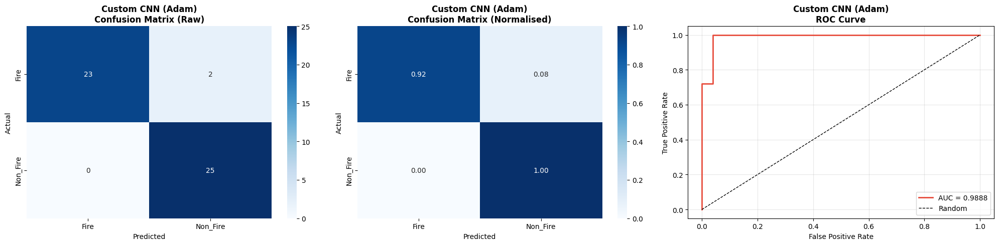

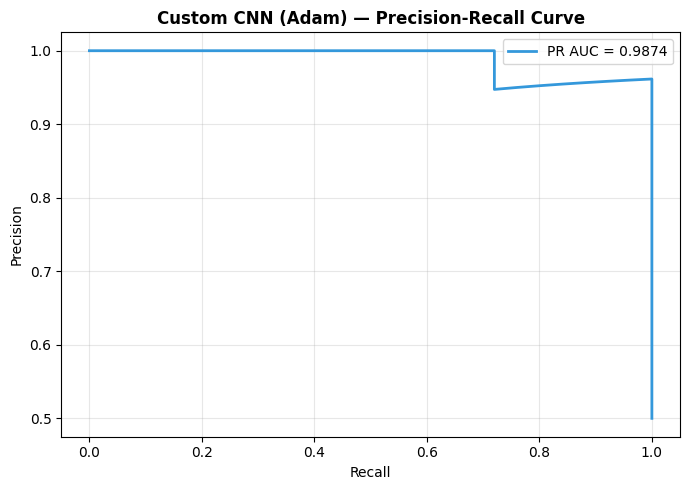


 Evaluating: Custom CNN (SGD)
  Accuracy   : 0.9600
  Precision  : 0.9600
  Recall     : 0.9600
  F1-Score   : 0.9600
  AUC-ROC    : 0.9888

  Classification Report:
              precision    recall  f1-score   support

        Fire       0.96      0.96      0.96        25
    Non_Fire       0.96      0.96      0.96        25

    accuracy                           0.96        50
   macro avg       0.96      0.96      0.96        50
weighted avg       0.96      0.96      0.96        50



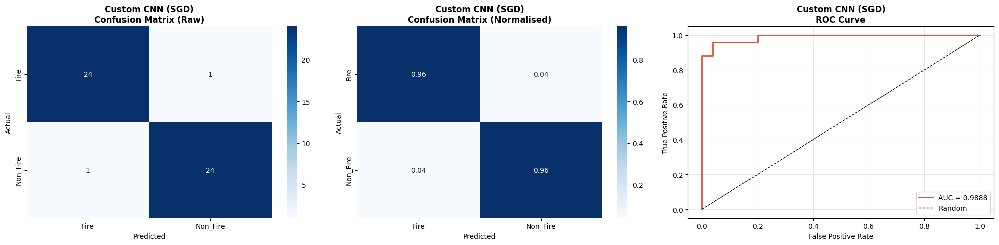

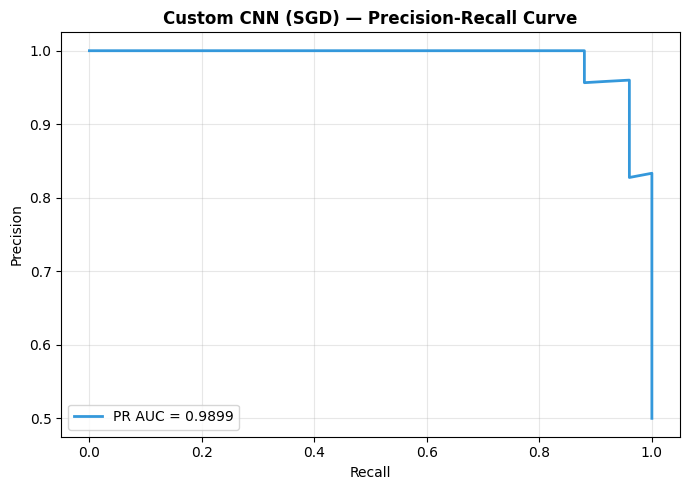


 Evaluating: MobileNetV2 TL
  Accuracy   : 0.8600
  Precision  : 0.9500
  Recall     : 0.7600
  F1-Score   : 0.8444
  AUC-ROC    : 0.9904

  Classification Report:
              precision    recall  f1-score   support

        Fire       0.80      0.96      0.87        25
    Non_Fire       0.95      0.76      0.84        25

    accuracy                           0.86        50
   macro avg       0.88      0.86      0.86        50
weighted avg       0.88      0.86      0.86        50



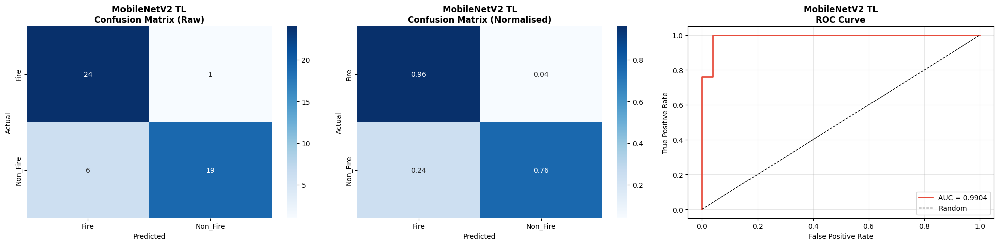

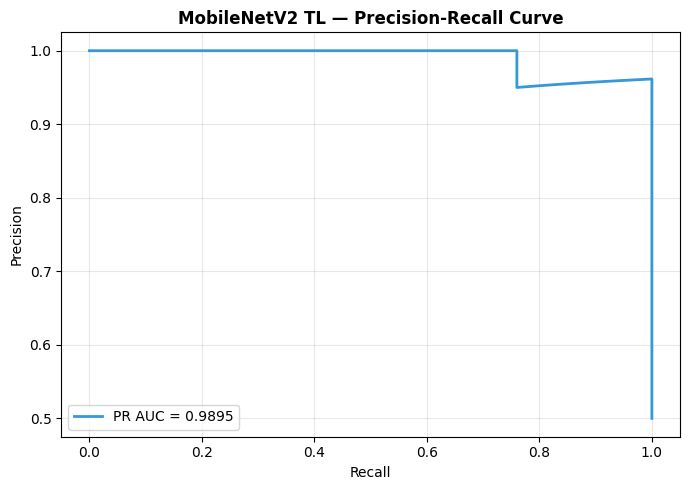


 Evaluating: ResNet50V2 TL
  Accuracy   : 0.9800
  Precision  : 1.0000
  Recall     : 0.9600
  F1-Score   : 0.9796
  AUC-ROC    : 1.0000

  Classification Report:
              precision    recall  f1-score   support

        Fire       0.96      1.00      0.98        25
    Non_Fire       1.00      0.96      0.98        25

    accuracy                           0.98        50
   macro avg       0.98      0.98      0.98        50
weighted avg       0.98      0.98      0.98        50



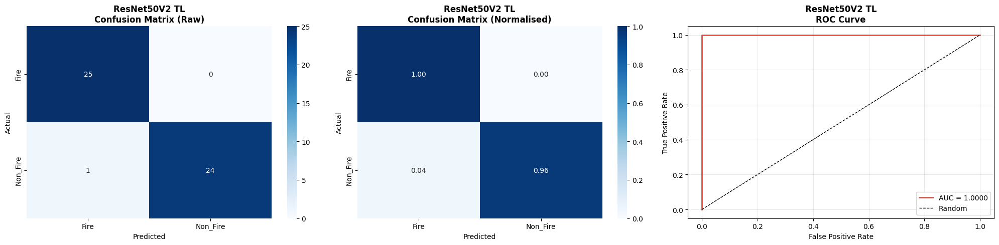

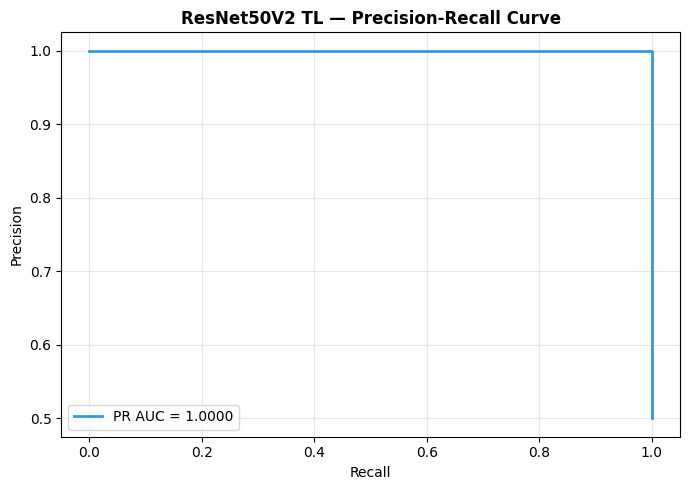


 Evaluating: EfficientNetB3 TL
  Accuracy   : 0.7600
  Precision  : 0.8095
  Recall     : 0.6800
  F1-Score   : 0.7391
  AUC-ROC    : 0.8512

  Classification Report:
              precision    recall  f1-score   support

        Fire       0.72      0.84      0.78        25
    Non_Fire       0.81      0.68      0.74        25

    accuracy                           0.76        50
   macro avg       0.77      0.76      0.76        50
weighted avg       0.77      0.76      0.76        50



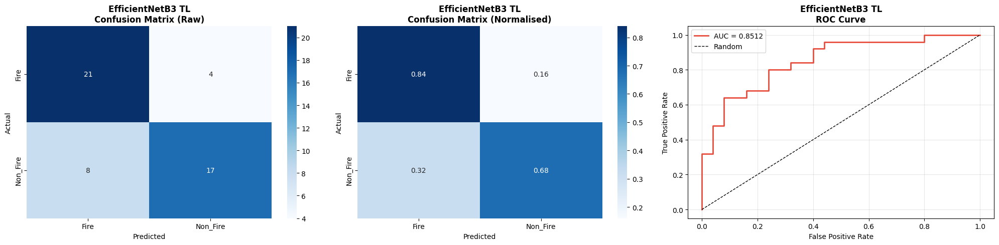

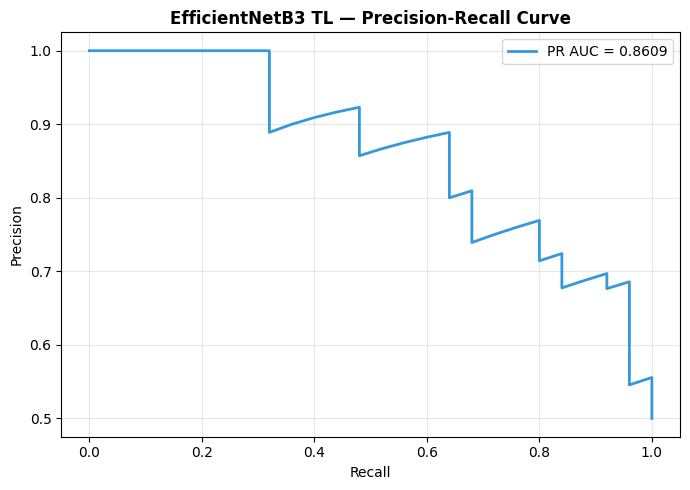

In [ ]:
def evaluate_model(model, generator, model_name='Model'):
    """
    Full evaluation pipeline:
    - Accuracy, Precision, Recall, F1-Score
    - Confusion Matrix
    - ROC Curve + AUC
    - Precision-Recall Curve
    Returns a dict of metrics.
    """
    print(f"\n{'='*60}")
    print(f" Evaluating: {model_name}")
    print(f"{'='*60}")

    generator.reset()
    y_pred_proba = model.predict(generator, verbose=0)
    y_true       = generator.classes

    if class_mode == 'binary':
        y_pred_proba_flat = y_pred_proba.ravel()
        y_pred_class      = (y_pred_proba_flat > 0.5).astype(int)
    else:
        y_pred_proba_flat = y_pred_proba[:, 1] if y_pred_proba.shape[1] == 2 else y_pred_proba.max(axis=1)
        y_pred_class      = np.argmax(y_pred_proba, axis=1)

    # ── Core metrics ──────────────────────────────────────────────────────
    acc       = accuracy_score(y_true, y_pred_class)
    prec      = precision_score(y_true, y_pred_class, zero_division=0)
    rec       = recall_score(y_true, y_pred_class, zero_division=0)
    f1        = f1_score(y_true, y_pred_class, zero_division=0)
    fpr, tpr, _ = roc_curve(y_true, y_pred_proba_flat)
    roc_auc   = auc(fpr, tpr)

    print(f"  Accuracy   : {acc:.4f}")
    print(f"  Precision  : {prec:.4f}")
    print(f"  Recall     : {rec:.4f}")
    print(f"  F1-Score   : {f1:.4f}")
    print(f"  AUC-ROC    : {roc_auc:.4f}")
    print(f"\n  Classification Report:")
    print(classification_report(y_true, y_pred_class,
                                 target_names=class_names, zero_division=0))

    # ── Plot Confusion Matrix ──────────────────────────────────────────────
    cm = confusion_matrix(y_true, y_pred_class)
    cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 3, figsize=(20, 5))

    # Raw CM
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title(f'{model_name}\nConfusion Matrix (Raw)', fontweight='bold')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('Actual')

    # Normalised CM
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[1])
    axes[1].set_title(f'{model_name}\nConfusion Matrix (Normalised)', fontweight='bold')
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('Actual')

    # ROC Curve
    axes[2].plot(fpr, tpr, color='#E74C3C', lw=2,
                 label=f'AUC = {roc_auc:.4f}')
    axes[2].plot([0,1],[0,1],'k--', lw=1, label='Random')
    axes[2].set_title(f'{model_name}\nROC Curve', fontweight='bold')
    axes[2].set_xlabel('False Positive Rate')
    axes[2].set_ylabel('True Positive Rate')
    axes[2].legend()
    axes[2].grid(alpha=0.3)

    plt.tight_layout()
    safe_name = model_name.lower().replace(' ', '_')
    plt.savefig(f'/content/{safe_name}_evaluation.png', dpi=150, bbox_inches='tight')
    plt.show()

    # ── Precision-Recall Curve ─────────────────────────────────────────────
    p_arr, r_arr, _ = precision_recall_curve(y_true, y_pred_proba_flat)
    pr_auc = auc(r_arr, p_arr)
    plt.figure(figsize=(7, 5))
    plt.plot(r_arr, p_arr, color='#3498DB', lw=2,
             label=f'PR AUC = {pr_auc:.4f}')
    plt.set_title = plt.title
    plt.title(f'{model_name} — Precision-Recall Curve', fontweight='bold')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'/content/{safe_name}_pr_curve.png', dpi=150, bbox_inches='tight')
    plt.show()

    return {
        'model': model_name, 'accuracy': acc, 'precision': prec,
        'recall': rec, 'f1': f1, 'auc_roc': roc_auc, 'pr_auc': pr_auc,
        'fpr': fpr, 'tpr': tpr, 'p_arr': p_arr, 'r_arr': r_arr
    }

# ── Evaluate all models ────────────────────────────────────────────────────
test_gen.reset()
results_cnn       = evaluate_model(best_cnn,       test_gen, 'Custom CNN (Adam)')
test_gen.reset()
results_sgd       = evaluate_model(sgd_cnn,        test_gen, 'Custom CNN (SGD)')
test_gen.reset()
results_mobilenet = evaluate_model(mobilenet_model, test_gen, 'MobileNetV2 TL')
test_gen.reset()
results_resnet     = evaluate_model(resnet_model,      test_gen, 'ResNet50V2 TL')

test_gen.reset()
results_efficientnet = evaluate_model(efficientnet_model, test_gen, 'EfficientNetB3 TL')

---
## 🏆 Section 8: Model Comparison Dashboard


📊 Model Comparison Summary
            Model  Accuracy  Precision  Recall  F1-Score  AUC-ROC  PR-AUC
Custom CNN (Adam)      0.96     0.9259    1.00    0.9615   0.9888  0.9874
 Custom CNN (SGD)      0.96     0.9600    0.96    0.9600   0.9888  0.9899
   MobileNetV2 TL      0.86     0.9500    0.76    0.8444   0.9904  0.9895
    ResNet50V2 TL      0.98     1.0000    0.96    0.9796   1.0000  1.0000
EfficientNetB3 TL      0.76     0.8095    0.68    0.7391   0.8512  0.8609


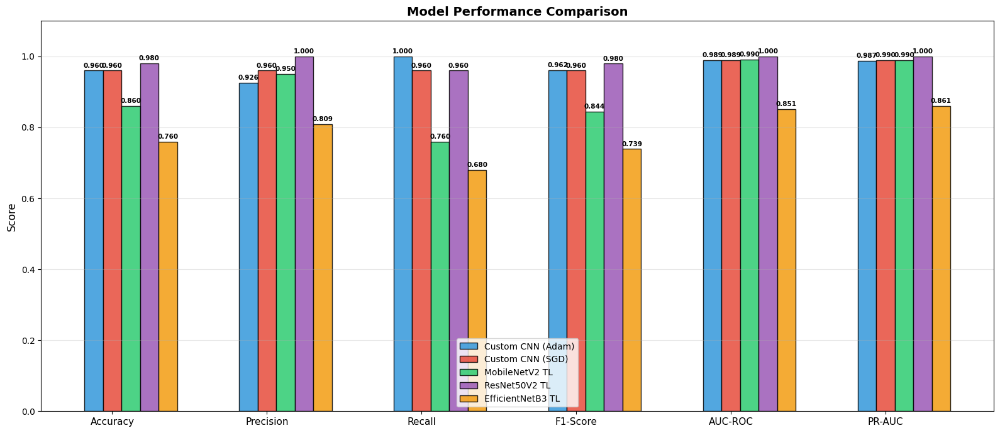

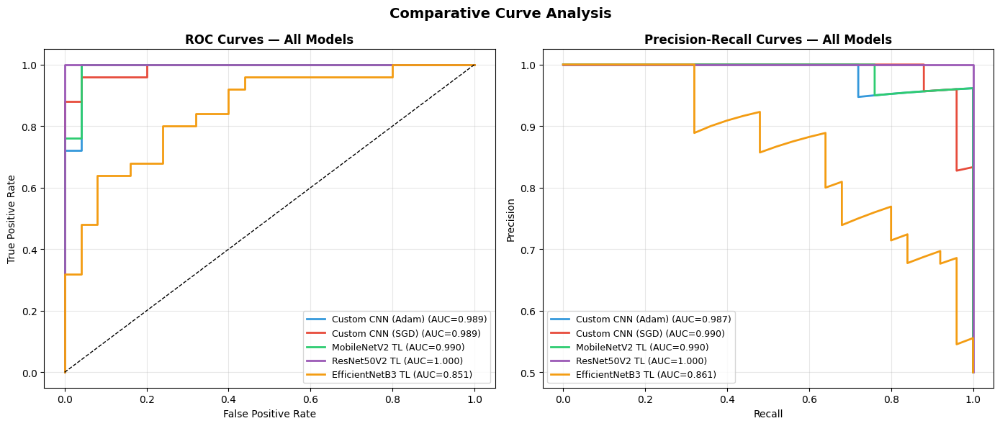

In [ ]:
# ── Build comparison summary table ────────────────────────────────────────
all_results = [results_cnn, results_sgd, results_mobilenet,
               results_resnet, results_efficientnet]
comparison_df = pd.DataFrame([{
    'Model'     : r['model'],
    'Accuracy'  : round(r['accuracy'],  4),
    'Precision' : round(r['precision'], 4),
    'Recall'    : round(r['recall'],    4),
    'F1-Score'  : round(r['f1'],        4),
    'AUC-ROC'   : round(r['auc_roc'],   4),
    'PR-AUC'    : round(r['pr_auc'],    4)
} for r in all_results])

print("\n📊 Model Comparison Summary")
print(comparison_df.to_string(index=False))

# ── Bar chart comparison ───────────────────────────────────────────────────
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC', 'PR-AUC']
x = np.arange(len(metrics))
width =  0.12
colors = ['#3498DB', '#E74C3C', '#2ECC71', '#9B59B6', '#F39C12', '#1ABC9C']

fig, ax = plt.subplots(figsize=(16, 7))
for i, row in comparison_df.iterrows():
    vals = [row[m] for m in metrics]
    bars = ax.bar(x + i * width, vals, width, label=row['Model'],
                  color=colors[i], edgecolor='black', alpha=0.85)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=7.5, fontweight='bold')

ax.set_xticks(x + width)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Model Performance Comparison', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('/content/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Overlay ROC curves ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for r, color in zip(all_results, colors):
    axes[0].plot(r['fpr'], r['tpr'], color=color, lw=2,
                 label=f"{r['model']} (AUC={r['auc_roc']:.3f})")
axes[0].plot([0,1],[0,1],'k--', lw=1)
axes[0].set_title('ROC Curves — All Models', fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

for r, color in zip(all_results, colors):
    axes[1].plot(r['r_arr'], r['p_arr'], color=color, lw=2,
                 label=f"{r['model']} (AUC={r['pr_auc']:.3f})")
axes[1].set_title('Precision-Recall Curves — All Models', fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

plt.suptitle('Comparative Curve Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/roc_pr_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 🖼️ Section 9: Prediction Visualization on Test Images

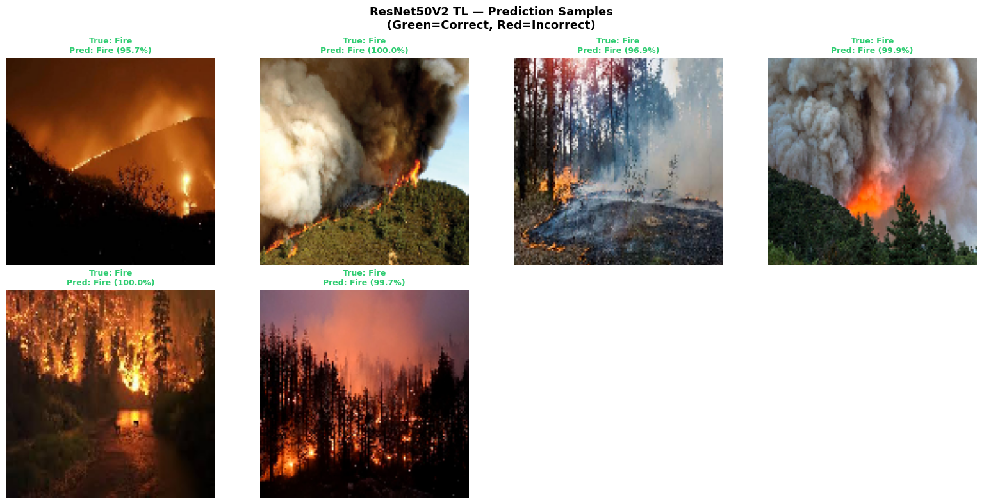

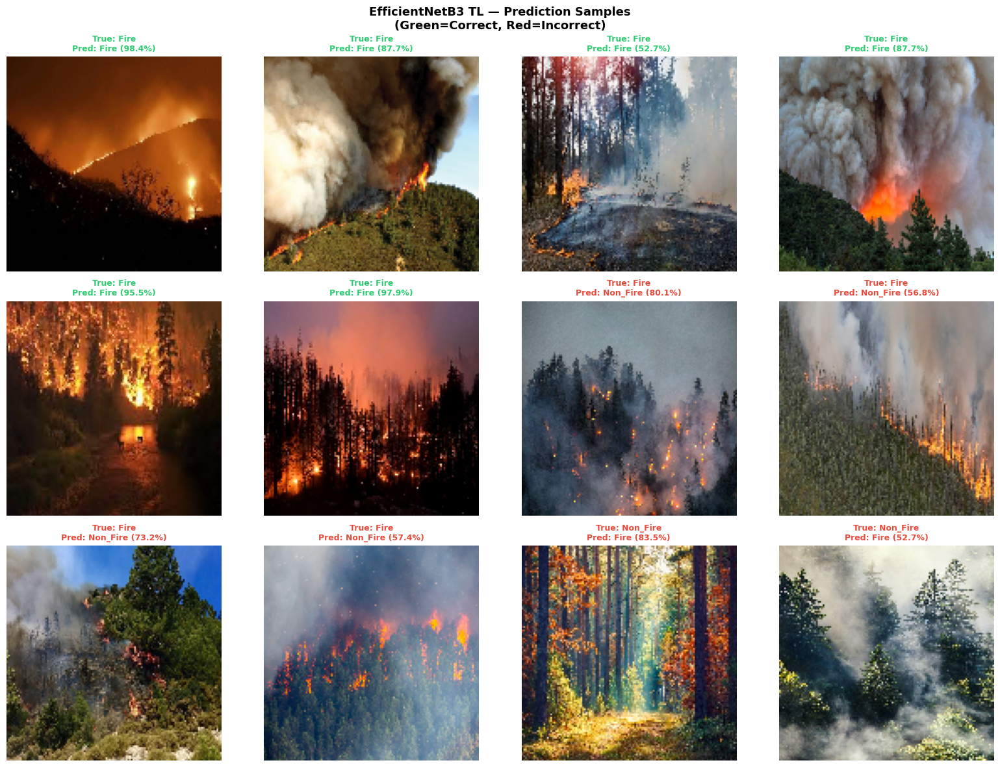

In [ ]:
# ── Visualize correct and incorrect predictions ────────────────────────────
def visualize_predictions(model, generator, model_name='Model', n=12):
    generator.reset()
    imgs, labels = [], []
    for batch_imgs, batch_labels in generator:
        imgs.append(batch_imgs)
        labels.extend(batch_labels.tolist())
        if len(labels) >= n * 3:
            break
    imgs = np.concatenate(imgs, axis=0)
    labels = np.array(labels)

    preds = model.predict(imgs[:n*3], verbose=0)
    if class_mode == 'binary':
        pred_class = (preds.ravel() > 0.5).astype(int)
        confidence = np.where(pred_class == 1, preds.ravel(), 1 - preds.ravel())
    else:
        pred_class = np.argmax(preds, axis=1)
        confidence = preds.max(axis=1)

    # Select mix of correct/incorrect
    correct_idx   = np.where(pred_class[:n*3] == labels[:n*3].astype(int))[0][:n//2]
    incorrect_idx = np.where(pred_class[:n*3] != labels[:n*3].astype(int))[0][:n//2]
    show_idx      = np.concatenate([correct_idx, incorrect_idx])[:n]

    cols = 4
    rows = (len(show_idx) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
    axes = axes.ravel() if rows > 1 else [axes] if cols == 1 else axes.ravel()

    for i, idx in enumerate(show_idx):
        true_lbl  = class_names[int(labels[idx])]
        pred_lbl  = class_names[pred_class[idx]]
        conf      = confidence[idx]
        correct   = (pred_class[idx] == int(labels[idx]))
        border    = '#2ECC71' if correct else '#E74C3C'

        axes[i].imshow(np.clip(imgs[idx], 0, 1))
        axes[i].axis('off')
        axes[i].set_title(
            f'True: {true_lbl}\nPred: {pred_lbl} ({conf:.1%})',
            fontsize=9,
            color=border,
            fontweight='bold'
        )
        for spine in axes[i].spines.values():
            spine.set_edgecolor(border)
            spine.set_linewidth(3)

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.suptitle(f'{model_name} — Prediction Samples\n'
                 '(Green=Correct, Red=Incorrect)',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    safe_name = model_name.lower().replace(' ', '_')
    plt.savefig(f'/content/{safe_name}_predictions.png', dpi=150, bbox_inches='tight')
    plt.show()


test_gen.reset()
visualize_predictions(resnet_model, test_gen, 'ResNet50V2 TL')

test_gen.reset()
visualize_predictions(efficientnet_model, test_gen, 'EfficientNetB3 TL')


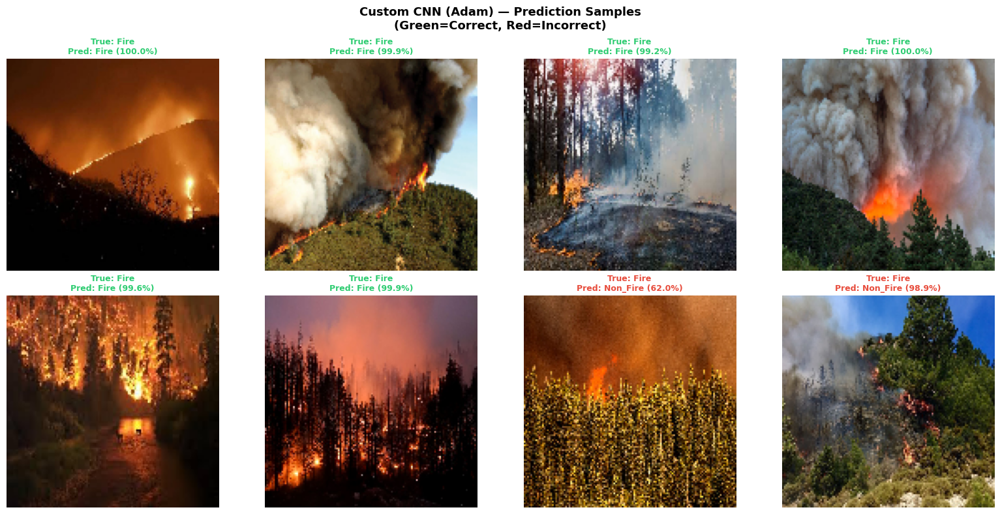

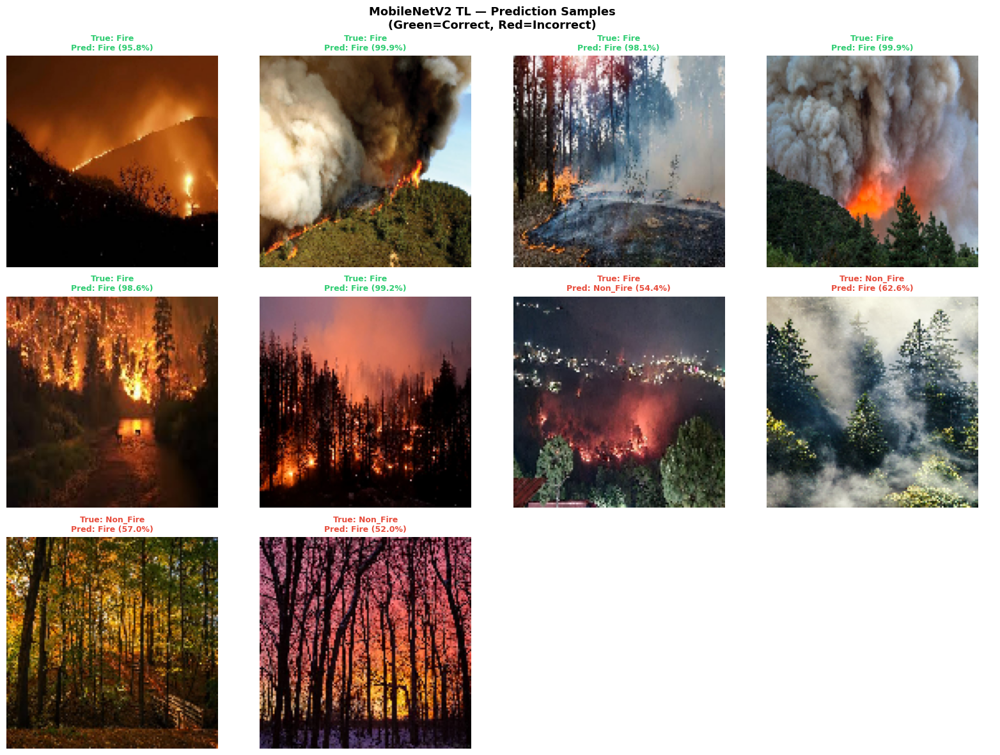

In [ ]:

test_gen.reset()
visualize_predictions(best_cnn, test_gen, 'Custom CNN (Adam)')
test_gen.reset()
visualize_predictions(mobilenet_model, test_gen, 'MobileNetV2 TL')

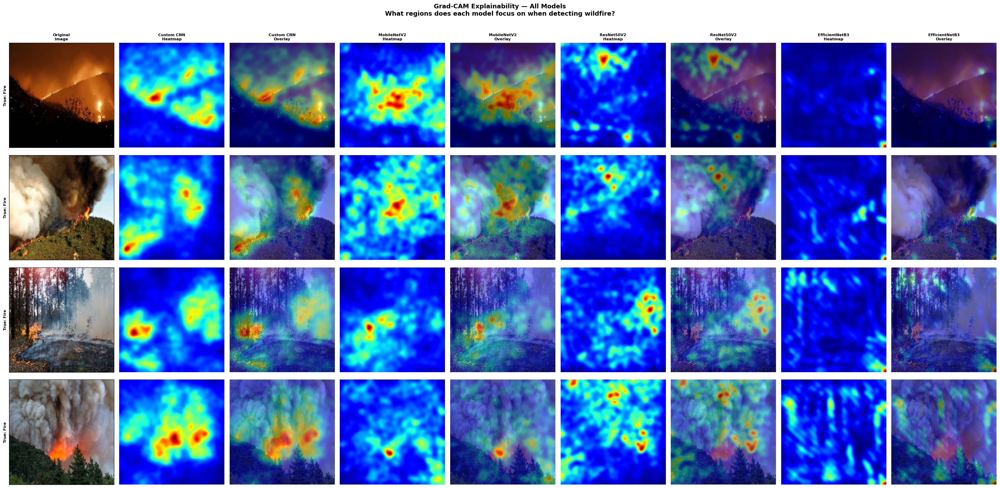

✅ Grad-CAM (all models) complete.


In [ ]:
# ══════════════════════════════════════════════════════════════════════════
#  Grad-CAM Explainability — All Models
# ══════════════════════════════════════════════════════════════════════════
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2

# ── Grad-CAM using input-gradient (saliency) approach ─────────────────────
def make_gradcam_heatmap(img_array, model, last_conv_layer_name=None):
    img_tensor = tf.cast(img_array, tf.float32)

    with tf.GradientTape() as tape:
        tape.watch(img_tensor)
        predictions = model(img_tensor, training=False)
        if class_mode == 'binary':
            loss = predictions[:, 0]
        else:
            loss = tf.reduce_max(predictions, axis=1)

    grads = tape.gradient(loss, img_tensor)

    # Keep only positive gradients (guided saliency)
    grads_positive = tf.nn.relu(grads)

    # Average across colour channels → (H, W)
    grads_map = tf.reduce_mean(grads_positive, axis=-1)[0].numpy()

    # Smooth with Gaussian blur
    grads_map = cv2.GaussianBlur(grads_map, (15, 15), 0)

    # Normalise to [0, 1]
    grads_map = (grads_map - grads_map.min()) / (grads_map.max() - grads_map.min() + 1e-8)

    return grads_map


def overlay_gradcam(original_img, heatmap, alpha=0.45):
    """original_img: float array (H, W, 3) in [0, 1]"""
    img             = np.uint8(255 * np.clip(original_img, 0, 1))
    heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap_uint8   = np.uint8(255 * heatmap_resized)
    heatmap_color   = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    heatmap_color   = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    overlaid        = np.uint8(img * (1 - alpha) + heatmap_color * alpha)
    return overlaid, heatmap_resized


# ── Helper: find the last Conv2D layer name ────────────────────────────────
def find_last_conv(model):
    for layer in reversed(model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            return layer.name
    for layer in reversed(model.layers):
        if hasattr(layer, 'layers'):
            for sublayer in reversed(layer.layers):
                if isinstance(sublayer, tf.keras.layers.Conv2D):
                    return sublayer.name
    return None


# ── Helper: get prediction label string ───────────────────────────────────
def get_pred_label(model, img_array):
    if class_mode == 'binary':
        conf = float(model.predict(img_array, verbose=0)[0][0])
        lbl  = 'fire' if conf > 0.5 else 'nofire'
        return f"{lbl} ({conf:.2f})"
    else:
        probs = model.predict(img_array, verbose=0)[0]
        idx   = int(np.argmax(probs))
        return f"{class_names[idx]} ({probs[idx]:.2f})"


# ── Models to visualise ────────────────────────────────────────────────────
model_entries = [
    ('Custom CNN',     best_cnn),
    ('MobileNetV2',    mobilenet_model),
    ('ResNet50V2',     resnet_model),
    ('EfficientNetB3', efficientnet_model),
]

# ── Collect 4 test images ──────────────────────────────────────────────────
test_gen.reset()
sample_imgs, sample_labels = next(test_gen)
sample_imgs   = sample_imgs[:4]
sample_labels = sample_labels[:4]

N_ROWS   = 4
N_MODELS = len(model_entries)
# Columns: original | heat_m1 | overlay_m1 | heat_m2 | overlay_m2 | ...
N_COLS   = 1 + N_MODELS * 2

fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(N_COLS * 3.2, N_ROWS * 3.5))

# ── Column headers ─────────────────────────────────────────────────────────
axes[0][0].set_title('Original\nImage', fontsize=8, fontweight='bold', pad=6)
col = 1
for name, _ in model_entries:
    axes[0][col].set_title(f'{name}\nHeatmap',  fontsize=8, fontweight='bold', pad=6)
    axes[0][col + 1].set_title(f'{name}\nOverlay', fontsize=8, fontweight='bold', pad=6)
    col += 2

# ── Row loop ───────────────────────────────────────────────────────────────
for row in range(N_ROWS):
    img       = sample_imgs[row]
    img_array = np.expand_dims(img, axis=0)

    if class_mode == 'binary':
        true_lbl = class_names[int(sample_labels[row])]
    else:
        true_lbl = class_names[int(np.argmax(sample_labels[row]))]

    # Col 0 — original image
    axes[row][0].imshow(np.clip(img, 0, 1))
    axes[row][0].set_ylabel(f'True: {true_lbl}', fontsize=8, fontweight='bold')
    axes[row][0].tick_params(left=False, bottom=False,
                              labelleft=False, labelbottom=False)

    col = 1
    for name, model in model_entries:
        pred_label = get_pred_label(model, img_array)

        try:
            heatmap          = make_gradcam_heatmap(img_array, model)
            overlay, heat_rs = overlay_gradcam(img, heatmap)
        except Exception as e:
            print(f"  {name} row {row} failed: {e}")
            heatmap  = np.zeros((img.shape[0], img.shape[1]))
            overlay  = np.uint8(255 * np.clip(img, 0, 1))
            heat_rs  = heatmap

        # Heatmap column
        axes[row][col].imshow(heatmap, cmap='jet', vmin=0, vmax=1)
        axes[row][col].set_xlabel(f'Pred: {pred_label}', fontsize=7)
        axes[row][col].axis('off')

        # Overlay column
        axes[row][col + 1].imshow(overlay)
        axes[row][col + 1].axis('off')

        col += 2

plt.suptitle(
    'Grad-CAM Explainability — All Models\n'
    'What regions does each model focus on when detecting wildfire?',
    fontsize=13, fontweight='bold', y=1.01
)
plt.tight_layout()
plt.savefig('/content/gradcam_all_models.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Grad-CAM (all models) complete.")

---
##  Section 10: Save Models & Download to Your Computer

> All files are saved locally in Colab's `/content/` session. Run the download cell to save them to your computer.

In [ ]:
# ── Save models and results to /content/ ──────────────────────────────────
import os

# ── Helper: safe save with existence check ────────────────────────────────
def safe_save_model(model, path):
    try:
        model.save(path)
        print(f"  ✅ Saved: {os.path.basename(path)}")
    except Exception as e:
        print(f"  ⚠️  Could not save {os.path.basename(path)}: {e}")

print("💾 Saving models...")
safe_save_model(best_cnn,           '/content/custom_cnn_final.keras')
safe_save_model(sgd_cnn,            '/content/sgd_cnn_final.keras')
safe_save_model(mobilenet_model,    '/content/mobilenet_tl_final.keras')
safe_save_model(resnet_model,       '/content/resnet50v2_tl_final.keras')
safe_save_model(efficientnet_model, '/content/efficientnetb3_tl_final.keras')

# ── Save CSV results ───────────────────────────────────────────────────────
try:
    comparison_df.to_csv('/content/model_comparison_results.csv', index=False)
    print("  ✅ Saved: model_comparison_results.csv")
except Exception as e:
    print(f"  ⚠️  Could not save CSV: {e}")

print("\n✅ All models and results saved to /content/")


💾 Saving models...
  ✅ Saved: custom_cnn_final.keras
  ✅ Saved: sgd_cnn_final.keras
  ✅ Saved: mobilenet_tl_final.keras
  ✅ Saved: resnet50v2_tl_final.keras
  ✅ Saved: efficientnetb3_tl_final.keras
  ✅ Saved: model_comparison_results.csv

✅ All models and results saved to /content/


In [ ]:
# ── Download all outputs directly to your computer ────────────────────────
# Each file triggers a browser download automatically in Google Colab.

import os
from google.colab import files

# ── Full list of expected output files ────────────────────────────────────
outputs_to_download = [
    # ── Saved models ──────────────────────────────────────────────────────
    '/content/custom_cnn_final.keras',
    '/content/sgd_cnn_final.keras',
    '/content/mobilenet_tl_final.keras',
    '/content/resnet50v2_tl_final.keras',
    '/content/efficientnetb3_tl_final.keras',

    # ── Results CSV ───────────────────────────────────────────────────────
    '/content/model_comparison_results.csv',

    # ── EDA & pre-processing plots ────────────────────────────────────────
    '/content/class_distribution.png',
    '/content/sample_images.png',
    '/content/class_weights.png',
    '/content/augmentation_preview.png',



    # ── Evaluation plots (safe_name pattern) ─────────────────────────────
    '/content/resnet50v2_tl_evaluation.png',
    '/content/resnet50v2_tl_pr_curve.png',
    '/content/efficientnetb3_tl_evaluation.png',
    '/content/efficientnetb3_tl_pr_curve.png',

    # ── Comparison & explainability ───────────────────────────────────────
    '/content/model_comparison.png',
    '/content/roc_pr_comparison.png',

    # ── Prediction visualizations ─────────────────────────────────────────

    '/content/resnet50v2_tl_predictions.png',
]

print("⬇️  Scanning and downloading output files...\n")

downloaded, missing = [], []

for filepath in outputs_to_download:
    if os.path.exists(filepath):
        try:
            files.download(filepath)
            downloaded.append(os.path.basename(filepath))
            print(f"  ✅ Downloaded : {os.path.basename(filepath)}")
        except Exception as e:
            print(f"  ❌ Failed     : {os.path.basename(filepath)} — {e}")
    else:
        missing.append(os.path.basename(filepath))
        print(f"  ⚠️  Not found  : {os.path.basename(filepath)}")

print(f"\n━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━")
print(f"✅ Downloaded : {len(downloaded)} file(s)")
print(f"⚠️  Not found  : {len(missing)} file(s)")
if missing:
    print("   (These files may not have been generated yet, or were saved")
    print("    under a slightly different name — see bonus scan below)")

# ── Bonus: scan /content/ for any extra .keras / .png / .csv / .h5 files ──
print("\n🔍 Scanning /content/ for any additional output files not listed above...")
listed = set(os.path.basename(p) for p in outputs_to_download)
extra = sorted([
    f for f in os.listdir('/content/')
    if f not in listed
    and (f.endswith('.keras') or f.endswith('.png')
         or f.endswith('.csv') or f.endswith('.h5'))
])
if extra:
    print(f"  Found {len(extra)} extra file(s) — downloading now:")
    for f in extra:
        try:
            files.download(f'/content/{f}')
            print(f"  ✅ Downloaded : {f}")
        except Exception as e:
            print(f"  ❌ Failed     : {f} — {e}")
else:
    print("  No additional files found.")

print("\n🎉 Done! All available files have been downloaded.")


⬇️  Scanning and downloading output files...



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  ✅ Downloaded : custom_cnn_final.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (102 outputs left out)

  ✅ Downloaded : mobilenetv2_tl_predictions.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  ✅ Downloaded : resnet_history.png

🎉 Done! All available files have been downloaded.


---
## ✅ Section 11: Requirements Checklist & Summary

In [ ]:
# ── Print final results and requirements checklist ─────────────────────────
print("="*70)
print(" FOREST & WILDFIRE DETECTION — PROJECT SUMMARY")
print("="*70)
# ── Load comparison_df ─────────────────────────────────────────────────────

print("\n" + "="*70)
print(" FINAL TEST SET RESULTS")
print("="*70)
print(comparison_df.to_string(index=False))

best_model_row = comparison_df.loc[comparison_df['F1-Score'].idxmax()]
print(f"\n🏆 Best Model (by F1-Score): {best_model_row['Model']}")
print(f"   F1-Score : {best_model_row['F1-Score']:.4f}")
print(f"   Accuracy : {best_model_row['Accuracy']:.4f}")
print(f"   AUC-ROC  : {best_model_row['AUC-ROC']:.4f}")
print("="*70)

 FOREST & WILDFIRE DETECTION — PROJECT SUMMARY

 FINAL TEST SET RESULTS
            Model  Accuracy  Precision  Recall  F1-Score  AUC-ROC  PR-AUC
Custom CNN (Adam)      0.96     0.9259    1.00    0.9615   0.9888  0.9874
 Custom CNN (SGD)      0.96     0.9600    0.96    0.9600   0.9888  0.9899
   MobileNetV2 TL      0.86     0.9500    0.76    0.8444   0.9904  0.9895
    ResNet50V2 TL      0.98     1.0000    0.96    0.9796   1.0000  1.0000
EfficientNetB3 TL      0.76     0.8095    0.68    0.7391   0.8512  0.8609

🏆 Best Model (by F1-Score): ResNet50V2 TL
   F1-Score : 0.9796
   Accuracy : 0.9800
   AUC-ROC  : 1.0000
